# Job Specialty 정규화 분석

## 목적
수집된 채용공고의 직무명(position)과 본문(main_tasks, requirements)을 분석하여
데이터 기반으로 job_specialty 분류 체계(taxonomy)를 도출한다.

## 접근 방법
1. 데이터 탐색: position, main_tasks, requirements 현황 파악
2. 텍스트 임베딩: sentence-transformers로 본문 벡터화
3. 클러스터링: UMAP + HDBSCAN으로 유사 직무 그룹핑
4. 클러스터 해석: 각 클러스터의 대표 키워드/업무 패턴 추출
5. Taxonomy 초안 도출

## 1. 데이터 로딩 및 탐색

In [6]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from collections import Counter

from utils.db import load_job_postings, get_engine

pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_rows', 100)

In [7]:
# 채용공고 데이터 로딩
df = load_job_postings(
    columns=[
        'id', 'position', 'position_detail',
        'main_tasks', 'requirements', 'preferred',
        'company_id', 'job_category_id'
    ],
    where="main_tasks IS NOT NULL AND requirements IS NOT NULL"
)

print(f"전체 공고 수: {len(df):,}")
print(f"\n컬럼별 null 현황:")
print(df.isnull().sum())
print(f"\n데이터 샘플:")
df.head(3)

전체 공고 수: 1,504

컬럼별 null 현황:
id                 0
position           0
position_detail    0
main_tasks         0
requirements       0
preferred          0
company_id         0
job_category_id    0
dtype: int64

데이터 샘플:


,id,position,position_detail,main_tasks,requirements,preferred,company_id,job_category_id
0,1034,[전문연구요원/산업기능요원] 백엔드 엔지니어,【 2026 코드잇 대규모 인재 채용 】*본 채용공고는 병역특례 대상자만 지원할 수 있어요.,[이런 일을 ​해요]1. ​코드잇 ​메인 서비스 ​개발 및 운영내부에서 만들어진 ​콘텐츠를 ​유저에게 제공하는 ​코드잇 메인 서비스의 ​API를 개발하고 ​운영합니다. ​메...,"[이런 분을 찾고 있어요]• 알고리즘과 자료구조에 대한 이해를 갖추신 분• 빠르게 학습하는 역량을 갖추신 분• 코드잇의 비전에 공감하며, 원활한 커뮤니케이션 능력을 갖추신 분",[이런 분이면 더 좋아요]• 컴퓨터 과학과 또는 컴퓨터 공학과 출신이신 분• 코드잇의 개발 스택(주요 업무에 기술됨)에 대한 전문성이 있으신 분• 영어를 잘 하시는 분 (B...,140,6
1,72,[AI반도체] Windows Driver Engineer,“모든 사물이 인공지능을 갖는 편리한 세상”모빌린트는 인공지능 기술의 무궁무진한 잠재력을 실현하여 더욱 편리하고 안전한 세상을 만들기 위해 2019년 설립된 AI 반도체 스...,• NPU 및 AI 가속기 활용을 위한 Windows 응용 프로그램 개발• Windows 환경에서의 제품 성능 테스트 및 검증• Windows 기반 시스템과 하드웨어 간 연...,"• Windows Driver(KMDF) 개발 경험• C, C++ 환경에서의 개발 경험• Windows API 에 대한 깊은 이해• 문제 해결 능력과 논리적 사고를 기반으로...",• Windows 프로그램 개발 경력 3년 이상• NPU/AI 가속기 관련 응용 프로그램 개발 경험• 멀티스레드 및 병렬 프로그래밍 경험• 고객 기술 지원 및 프로젝트 협업...,54,1
2,798,AI 플랫폼 엔지니어,"AI의 성공을 함께 만들어갈 MLOps/AI 플랫폼 엔지니어를 모십니다.우리 팀은 AI 모델러가 오직 모델 개발에만 집중할 수 있도록, AI 모델의 학습과 배포 과정을 자동...","• AI 서비스의 핵심 파이프라인 구축 : 대용량 데이터를 효율적으로 처리하고, AI 모델의 학습 및 배포 과정을 자동화하는 데이터/ML 파이프라인을 설계하고 구현합니다.•...","• 경력 ​: 2년 ​이상• Airflow를 활용한 데이터 또는 ML 파이프라인 설계 및 운영 경험이 있는 분 • Kubernetes, Ansible 등 컨테이너 기반 서비...","• MLFlow, Kubeflow 등 MLOps 관련 기술을 활용한 플랫폼 구축 경험이 있으신 분 • Apache Flink 등 실시간 스트리밍 처리 기술을 활용한 데이터...",52,4


In [8]:
# job_categories 테이블 조인하여 job_field(원티드 직무) 확인
from sqlalchemy import text

engine = get_engine()
jc_df = pd.read_sql(
    text("SELECT job_category_id, job_category, job_field, job_specialty FROM job_categories"),
    engine
)
print(f"job_categories 레코드 수: {len(jc_df)}")
print(f"\njob_field(원티드 직무) 분포:")
print(jc_df['job_field'].value_counts())
print(f"\njob_specialty 현황:")
print(jc_df['job_specialty'].value_counts().head(20))

job_categories 레코드 수: 6

job_field(원티드 직무) 분포:
job_field
머신러닝 엔지니어     1
데이터 사이언티스트    1
빅데이터 엔지니어     1
파이썬 개발자       1
데이터 엔지니어      1
서버 개발자        1
Name: count, dtype: int64

job_specialty 현황:
Series([], Name: count, dtype: int64)


In [9]:
# df에 job_field 조인
df = df.merge(jc_df[['job_category_id', 'job_field']], on='job_category_id', how='left')
print(f"job_field별 공고 수:")
print(df['job_field'].value_counts())

job_field별 공고 수:
job_field
서버 개발자        517
머신러닝 엔지니어     482
파이썬 개발자       268
데이터 사이언티스트    104
데이터 엔지니어       90
빅데이터 엔지니어      43
Name: count, dtype: int64


### 1.1 position(채용공고 제목) 현황 분석

In [10]:
# 원본 position 빈도 분석
position_counts = df['position'].value_counts()
print(f"고유 position 수: {len(position_counts):,}")
print(f"\n상위 30개 position:")
print(position_counts.head(30))
print(f"\n1회만 등장하는 position 수: {(position_counts == 1).sum()}")

고유 position 수: 1,335

상위 30개 position:
position
백엔드 개발자                       28
Backend Engineer              15
백엔드 엔지니어                      12
Data Engineer                 12
데이터 엔지니어                      11
Data Scientist                10
AI 엔지니어                        9
AI Engineer                    9
풀스택 개발자                        8
AI Agent Engineer              6
AI Research Engineer           5
Senior Backend Engineer        5
소프트웨어 엔지니어                     5
MLOps Engineer                 4
Software Engineer              4
Data Analyst                   4
Machine Learning Engineer      3
데이터 사이언티스트                     3
Field Application Engineer     3
AI Product Engineer            3
AI 개발자                         3
백엔드 개발자 (5년 이상)                3
[인턴] AI Engineer               2
Sr. Backend Engineer           2
AI 서비스 백엔드 개발자                 2
백엔드/서버 개발자                     2
LLM 엔지니어                       2
ML 엔지니어                        2
Back-end Engineer           

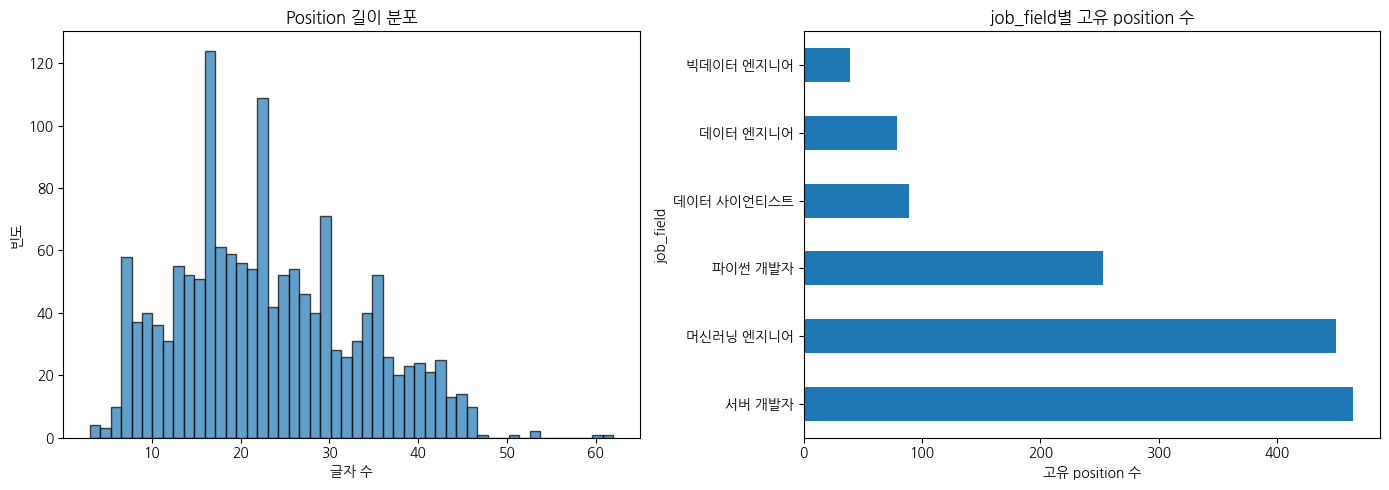

In [11]:
# position 길이 분포
df['position_len'] = df['position'].str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['position_len'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title('Position 길이 분포')
axes[0].set_xlabel('글자 수')
axes[0].set_ylabel('빈도')

# job_field별 position 다양성
diversity = df.groupby('job_field')['position'].nunique().sort_values(ascending=False)
diversity.plot(kind='barh', ax=axes[1])
axes[1].set_title('job_field별 고유 position 수')
axes[1].set_xlabel('고유 position 수')

plt.tight_layout()
plt.show()

### 1.2 본문(main_tasks, requirements) 텍스트 현황

In [12]:
# 본문 텍스트 길이 분포
df['main_tasks_len'] = df['main_tasks'].str.len()
df['requirements_len'] = df['requirements'].str.len()
df['preferred_len'] = df['preferred'].fillna('').str.len()

print("텍스트 길이 통계:")
print(df[['main_tasks_len', 'requirements_len', 'preferred_len']].describe())

# 분석용 통합 텍스트 생성
df['combined_text'] = (
    df['main_tasks'].fillna('') + ' ' +
    df['requirements'].fillna('') + ' ' +
    df['preferred'].fillna('')
).str.strip()

df['combined_len'] = df['combined_text'].str.len()
print(f"\n통합 텍스트 길이 통계:")
print(df['combined_len'].describe())

텍스트 길이 통계:
       main_tasks_len  requirements_len  preferred_len
count     1504.000000       1504.000000    1504.000000
mean       312.436835        242.180186     235.636968
std        249.876065        137.305813     190.257688
min          6.000000         11.000000       0.000000
25%        146.000000        149.750000     127.000000
50%        240.000000        222.500000     202.000000
75%        402.250000        303.000000     284.000000
max       2433.000000       1156.000000    1912.000000

통합 텍스트 길이 통계:
count    1504.000000
mean      792.233378
std       424.069703
min        18.000000
25%       502.750000
50%       715.000000
75%       983.250000
max      3958.000000
Name: combined_len, dtype: float64


In [13]:
# 샘플 확인: 다양한 position들의 실제 본문 비교
sample_positions = df.sample(5, random_state=42)[['position', 'job_field', 'main_tasks', 'requirements']]
for _, row in sample_positions.iterrows():
    print(f"\n{'='*80}")
    print(f"Position: {row['position']}")
    print(f"Job Field: {row['job_field']}")
    print(f"\n[주요업무] {row['main_tasks'][:300]}")
    print(f"\n[자격요건] {row['requirements'][:300]}")


Position: AI Engineer (5~10년)
Job Field: 파이썬 개발자

[주요업무] "자타공인 개발 잘한다는 소리 좀 듣는데, AI 서비스에 관심 또한 있으신 분을 찾고 있습니다."리얼드로우의 AI Engineer는 이미지 생성 AI에 대한 새로운 연구를 기반으로 정확한 학습데이터를 규정하고, 적은 학습데이터로 작가의 의도를 정확히 구현하는 모델링을 담당합니다. 때문에 리서치에 대한 탐구와 집착에서 시작하여 연구 결과를 엔지니어링으로 구현할 수 있는 분을 찾고 있습니다.＜리얼드로우 AI Engineer로 일하며 얻을 수 있는 것＞• Gen AI 기술이 웹툰 제작과 매출로 이어지는 과정을 눈앞에서 확인하며, 추상적인

[자격요건] ＜Tech팀 기술 스택＞• 주요 기술 : Java, Spring Framework, Gradle, Pytorch, FastAPI, Python, Kotiln, Nextjs, React, Nodejs, TypeScript• 저장소 : MySQL, Mongodb• 업무 도구 : Git, Github, IntelliJ IDEA Ultimate, Docker, GitHub Copilot, Comfyui• 코드 리뷰 / 코드 품질 관리 : Github, SonarQube, Pylint, Black, Eslint• 테스트, 빌드, 배포 : J

Position: 백엔드 개발자 (미들급)
Job Field: 데이터 엔지니어

[주요업무] 1. 충전 서비스 백엔드 개발• CSMS(Charging Station Management System) 핵심 기능 개발• 충전/회원/결제 도메인 API 설계 및 개발• 대용량 트래픽 처리를 위한 성능 최적화 2. MSA 전환 및 고도화• 모놀리식 서비스의 MSA 분리 작업 참여• 마이크로서비스 간 통신 설계 및 구현• 서비스 안정성 및 확장성 개선 3. 데이터베이스 설계 및 운영• PostgreSQL, Oracle 기반 DB 설계 및 쿼리 최적화• 데이터 마이그레이션 작업 참여• 대용량 데이터

### 1.3 job_field별 본문 패턴 분석

클러스터링 전에, 이미 알고 있는 분류(원티드 job_field 6개)의 본문이 실제로 어떻게 다른지 파악한다.
job_field 간 차별적 키워드를 먼저 이해해야 클러스터링 결과를 해석할 수 있다.

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import re

def get_discriminative_keywords(df, group_col, text_col='combined_text', top_n=15):
    """
    각 그룹별 '다른 그룹 대비' 차별적인 키워드 추출 (c-TF-IDF 방식)
    단순 TF-IDF가 아니라, 해당 그룹에서의 빈도 vs 전체 빈도의 비율로 차별성을 측정
    """
    groups = sorted(df[group_col].unique())
    
    # 불용어: 채용공고에서 직무 구분에 도움 안 되는 일반적 단어
    stopwords = {
        # 채용공고 공통 표현
        '경험', '이상', '우대', '관련', '개발', '업무', '경력', '능력',
        '이해', '기반', '활용', '환경', '기술', '서비스', '프로젝트',
        '가능', '역할', '수행', '담당', '필요', '보유', '사용',
        '분야', '협업', '문제', '해결', '작성', '설계', '구축',
        '운영', '지원', '참여', '진행', '등의', '및', '또는',
        '위한', '대한', '통한', '따른', '소통', '커뮤니케이션', '통계적', '개인적',
        '이해관계자들과', '담당해요.', '출장에', 'https', 'http', '이용해', '개발해요.',
        
        # 일반 동사/형용사/부사 (키워드로 무의미)
        '보며', '낮추는', '리드할', '리딩할', '소통하고', '처리하기',
        '만들어', '통해', '함께', '되는', '있는', '하는', '위해',
        '좋은', '높은', '새로운', '다양한', '적극적', '원활한',
        '깊은', '폭넓은', '뛰어난', '빠른', '효율적', '안정적',
        # 일반 명사 (직무 구분 무관)
        '개발경험', '신기술에', '이전', '분기술', '권한설정', '러닝커브를',
        '팀원', '조직', '성장', '리더', '매니저', '팀장',
        '회사', '스타트업', '글로벌', '국내', '해외',
        '제품', '플랫폼', '시스템', '솔루션', '아키텍처',
        '테스트', '코드', '리뷰', '문서화', '배포', '모니터링',
        '최적화', '자동화', '유지보수', '트러블슈팅',
        '커뮤니케이션', '의사소통', '논리적', '주도적',
        '식음료', '좋겠어요.', '패스오더가', '방법에', '구축해요.'
    }
    
    # 그룹별 텍스트 합치기
    group_texts = []
    for g in groups:
        texts = df[df[group_col] == g][text_col].tolist()
        group_texts.append(' '.join(texts))
    
    vectorizer = TfidfVectorizer(
        max_features=5000,
        token_pattern=r'(?u)[a-zA-Z가-힣][a-zA-Z가-힣.#+]+',
        min_df=1
    )
    tfidf_matrix = vectorizer.fit_transform(group_texts)
    feature_names = vectorizer.get_feature_names_out()
    
    # 각 그룹의 TF-IDF 벡터
    tfidf_dense = tfidf_matrix.toarray()
    
    # 차별성 점수: 해당 그룹 TF-IDF / 다른 그룹 평균 TF-IDF
    results = {}
    for i, g in enumerate(groups):
        group_scores = tfidf_dense[i]
        other_mean = np.mean(np.delete(tfidf_dense, i, axis=0), axis=0)
        # 0으로 나누기 방지: 다른 그룹에 아예 없는 단어는 차별성 상한(100x)으로 제한
        other_mean_safe = np.where(other_mean == 0, 1e-10, other_mean)
        discriminative = group_scores / other_mean_safe
        discriminative = np.clip(discriminative, 0, 100)  # 상한 100x
        
        # 최소 TF-IDF 필터 (너무 희귀한 단어 제외)
        discriminative = np.where(group_scores < 0.01, 0, discriminative)
        
        top_indices = discriminative.argsort()[::-1]
        keywords = []
        for idx in top_indices:
            word = feature_names[idx]
            if word in stopwords or len(word) <= 1:
                continue
            # 한글 1~2글자 동사/조사 패턴 제거 (ex: 보며, 하고, 되는)
            if re.match(r'^[가-힣]{1,3}(하고|하며|하는|되는|보며|위해|통해|에서|으로|에는|할|를|의|고|며)$', word):
                continue
            # 너무 짧은 한글 단어 (2글자 이하) 중 의미 약한 것 필터
            if len(word) <= 2 and re.match(r'^[가-힣]+$', word):
                continue
            keywords.append((word, group_scores[idx], discriminative[idx]))
            if len(keywords) >= top_n:
                break
        results[g] = keywords
    
    return results


# job_field별 차별적 키워드 분석
field_keywords = get_discriminative_keywords(df, 'job_field')

for field, keywords in field_keywords.items():
    count = (df['job_field'] == field).sum()
    print(f"\n{'='*80}")
    print(f"[{field}] ({count}건)")
    print(f"  차별적 키워드 (이 직무에서만 특히 많이 등장):")
    for word, tfidf, disc in keywords:
        print(f"    {word:20s}  (TF-IDF: {tfidf:.3f}, 차별성: {disc:.1f}x)")


[데이터 사이언티스트] (104건)
  차별적 키워드 (이 직무에서만 특히 많이 등장):
    cohort                (TF-IDF: 0.017, 차별성: 100.0x)
    analyst               (TF-IDF: 0.013, 차별성: 100.0x)
    funnel                (TF-IDF: 0.015, 차별성: 100.0x)
    마트와                   (TF-IDF: 0.011, 차별성: 100.0x)
    snowflake를            (TF-IDF: 0.011, 차별성: 100.0x)
    일관되게                  (TF-IDF: 0.011, 차별성: 100.0x)
    dbt를                  (TF-IDF: 0.014, 차별성: 100.0x)
    코호트                   (TF-IDF: 0.019, 차별성: 100.0x)
    aarrr                 (TF-IDF: 0.021, 차별성: 100.0x)
    지표와                   (TF-IDF: 0.016, 차별성: 48.1x)
    마이닝                   (TF-IDF: 0.012, 차별성: 25.3x)
    리텐션                   (TF-IDF: 0.013, 차별성: 17.5x)
    개인화                   (TF-IDF: 0.018, 차별성: 16.6x)
    기반한                   (TF-IDF: 0.010, 차별성: 14.6x)
    대시보드를                 (TF-IDF: 0.015, 차별성: 14.5x)

[데이터 엔지니어] (90건)
  차별적 키워드 (이 직무에서만 특히 많이 등장):
    qualifications        (TF-IDF: 0.011, 차별성: 13.7x)
    redshift              (T

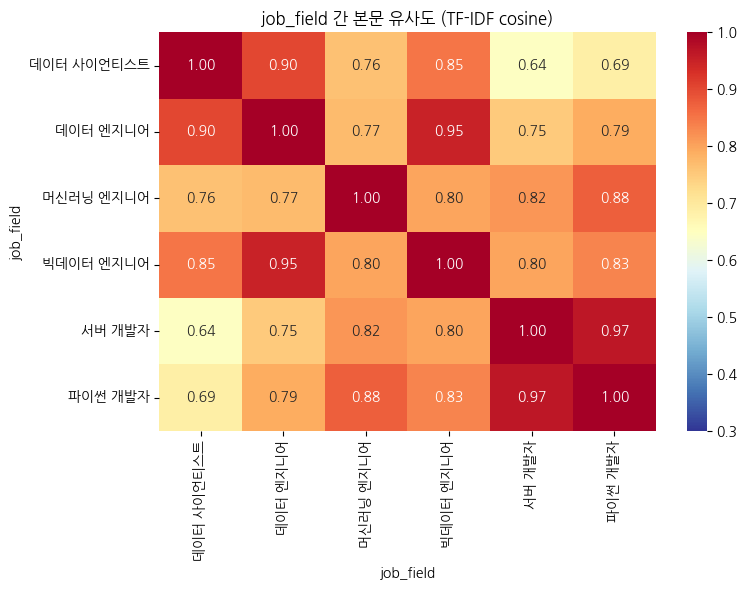


해석: 유사도가 높은 쌍 = 원티드 분류로는 구분되지만 본문은 비슷한 직무
→ 이런 쌍은 job_specialty 분류에서 더 세밀한 기준이 필요


In [58]:
# job_field 간 본문 유사도: 원티드 분류가 실제로 본문 기준으로 구분되는지 확인
from sklearn.metrics.pairwise import cosine_similarity

# job_field별 평균 TF-IDF 벡터 비교
field_vectorizer = TfidfVectorizer(
    max_features=3000,
    token_pattern=r'(?u)[a-zA-Z가-힣][a-zA-Z가-힣.#+]+',
)
field_groups = df.groupby('job_field')['combined_text'].apply(' '.join)
field_tfidf = field_vectorizer.fit_transform(field_groups)
field_sim = cosine_similarity(field_tfidf)

field_sim_df = pd.DataFrame(
    field_sim,
    index=field_groups.index,
    columns=field_groups.index
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(field_sim_df, annot=True, fmt='.2f', cmap='RdYlBu_r', ax=ax,
            vmin=0.3, vmax=1.0)
ax.set_title('job_field 간 본문 유사도 (TF-IDF cosine)')
plt.tight_layout()
plt.show()

print("\n해석: 유사도가 높은 쌍 = 원티드 분류로는 구분되지만 본문은 비슷한 직무")
print("→ 이런 쌍은 job_specialty 분류에서 더 세밀한 기준이 필요")

### 1.4 "파이썬 개발자" 직무 세분화 분석

원티드의 "파이썬 개발자"는 로봇/제어, Django 백엔드, 양자컴퓨팅, 하드웨어 등
전혀 다른 직무가 섞여 있어 세분화가 필수. 제목(position)에서 나타나는 실제 직무 패턴을 분석한다.

In [59]:
# "파이썬 개발자" job_field에 속한 공고들의 position 분석
python_df = df[df['job_field'] == '파이썬 개발자'].copy()

print(f"파이썬 개발자 공고 수: {len(python_df)}")
print(f"전체 position 목록 (빈도순):")
for pos, cnt in python_df['position'].value_counts().items():
    print(f"  {cnt:3d}건  {pos}")

파이썬 개발자 공고 수: 268
전체 position 목록 (빈도순):
    7건  백엔드 개발자
    4건  Backend Engineer
    2건  Sr. Backend Engineer
    2건  Backend Developer (5년이상)
    2건  Senior Backend Engineer
    2건  Python Developer
    2건  DevOps Engineer
    2건  Field Application Engineer
    1건  AI 플랫폼 엔지니어
    1건  지방자치단체 민원처리 AI시스템 개발자 (Backend/Full Stack)
    1건  [America Tech] AI Software Engineer
    1건  [프리랜서] 하나은행_글로벌 준법 시스템 SI
    1건  백엔드 엔지니어
    1건  AI Engineer (5~10년)
    1건  Algorithm Engineer
    1건  [서울]Backend engineer 백앤드 개발자(0~3년)
    1건  시스템2 Backend Lead (Tech Lead)
    1건  [연구개발] LLM RAG 시스템 개발자 (3년 이상)
    1건  PM/PL
    1건  Sr. AI 및 데이터 분석 전문가
    1건  Product Engineer(BE)
    1건  풀스택/백엔드 엔지니어 (5년 이상)
    1건  Embedded Linux SW Engineer
    1건  [오디바이스] 백엔드 엔지니어 (1~5년)
    1건  백엔드 개발자 (6~10년)
    1건  [인턴] [오디바이스] 백엔드 엔지니어
    1건  백엔드개발팀 백엔드개발자
    1건  [EC솔루션연구소] AI 기술 개발자 (전문연구요원 현역)
    1건  [EC솔루션연구소] AI 기술 개발자
    1건  공식몰 개발자 (주니어)
    1건  Python기반 백엔드 개발자 (3년 이상)
    1건  Service Backend 개발자
    

**해석**: "파이썬 개발자"라는 하나의 job_field 안에 백엔드, 데이터 엔지니어링, 로봇/임베디드, 머신러닝, DevOps 등
전혀 다른 도메인의 공고가 혼재되어 있다. 원티드의 직무 분류(job_field)만으로는 실제 직무를 구분할 수 없으며,
이는 "파이썬 개발자"뿐 아니라 다른 job_field에서도 동일한 문제가 존재할 가능성을 시사한다.

→ **공고 본문(텍스트) 기반의 직무 재분류가 필요하다.**

## 2. 텍스트 임베딩 & 클러스터링 파이프라인

위 분석에서 확인했듯이, 원티드의 job_field 분류는 실제 직무 경계와 일치하지 않는다.
position(제목)만으로도 혼재를 확인할 수 있지만, 제목이 모호한 공고도 많기 때문에
**공고 본문 전체를 임베딩하여 의미적 유사도 기반으로 클러스터링**하는 접근이 필요하다.

그런데 임베딩 모델마다 학습 데이터와 언어 지원 범위가 다르고, 한국어·영어가 혼재된 채용 공고 텍스트에서
어떤 모델이 직무 간 의미 차이를 가장 잘 포착하는지는 사전에 알 수 없다.
따라서 다국어 모델과 영어 특화 모델을 포함한 여러 임베딩 모델로 각각 클러스터링을 수행하고,
클러스터 품질 지표(실루엣 스코어, 노이즈 비율 등)를 비교하여 최적의 모델을 선택한다.

파이프라인 구성: 임베딩 → UMAP 차원 축소 → HDBSCAN 클러스터링 → 평가.
각 모델 결과를 저장해두고, 마지막에 비교표와 시각화로 최적 모델을 선택한다.

In [ ]:
import umap
import hdbscan
import time

import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer
from sklearn.metrics import silhouette_score
from dataclasses import dataclass, field as dc_field

@dataclass
class ModelResult:
    """한 모델의 임베딩 + 클러스터링 결과를 담는 컨테이너"""
    model_name: str
    embed_dim: int
    embed_time: float          # 임베딩 소요 시간(초)
    embeddings: np.ndarray     # (n, dim)
    umap_2d: np.ndarray        # (n, 2) 시각화용
    cluster_labels: np.ndarray # HDBSCAN 결과
    n_clusters: int
    noise_pct: float           # 노이즈 비율
    silhouette: float          # 실루엣 점수 (클러스터 품질)
    purity_mean: float         # 클러스터-job_field 평균 순도
    purity_scores: list = dc_field(default_factory=list)


def run_pipeline(texts, model_name, job_fields,
                 umap_dim=15, min_cluster_size=10, min_samples=5):
    """
    임베딩 → UMAP → HDBSCAN → 평가 지표 계산을 한번에 수행
    
    Args:
        texts: 임베딩할 텍스트 리스트
        model_name: sentence-transformers 모델명
        job_fields: job_field 시리즈 (순도 계산용)
    
    Returns:
        ModelResult
    """
    # 1. 임베딩
    print(f"\n{'='*60}")
    print(f"모델: {model_name}")
    
    model = SentenceTransformer(model_name)
    embed_dim = model.get_sentence_embedding_dimension()
    print(f"  차원: {embed_dim}")
    
    t0 = time.time()
    emb = model.encode(texts, show_progress_bar=True, batch_size=64,
                       normalize_embeddings=True)
    embed_time = time.time() - t0
    print(f"  임베딩 완료: {embed_time:.1f}초")
    
    # 2. UMAP (클러스터링용 + 시각화용)
    umap_cluster = umap.UMAP(
        n_components=umap_dim, n_neighbors=15, min_dist=0.0,
        metric='cosine', random_state=42
    ).fit_transform(emb)
    
    umap_2d = umap.UMAP(
        n_components=2, n_neighbors=15, min_dist=0.1,
        metric='cosine', random_state=42
    ).fit_transform(emb)
    
    # 3. HDBSCAN
    labels = hdbscan.HDBSCAN(
        min_cluster_size=min_cluster_size, min_samples=min_samples,
        metric='euclidean', cluster_selection_method='eom'
    ).fit_predict(umap_cluster)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).sum() / len(labels)
    
    # 4. 실루엣 점수 (노이즈 제외)
    mask = labels != -1
    if mask.sum() > 1 and n_clusters > 1:
        sil = silhouette_score(umap_cluster[mask], labels[mask])
    else:
        sil = -1.0
    
    # 5. 클러스터-job_field 순도
    purity_list = []
    for c in set(labels):
        if c == -1:
            continue
        c_fields = job_fields[labels == c]
        purity = c_fields.value_counts().iloc[0] / len(c_fields)
        purity_list.append(purity)
    purity_mean = np.mean(purity_list) if purity_list else 0
    
    print(f"  클러스터: {n_clusters}개, 노이즈: {noise_pct:.1%}, "
          f"실루엣: {sil:.3f}, 평균순도: {purity_mean:.2%}")
    
    # 메모리 해제
    del model
    
    return ModelResult(
        model_name=model_name, embed_dim=embed_dim, embed_time=embed_time,
        embeddings=emb, umap_2d=umap_2d, cluster_labels=labels,
        n_clusters=n_clusters, noise_pct=noise_pct, silhouette=sil,
        purity_mean=purity_mean, purity_scores=purity_list
    )


# 비교할 모델 목록
MODELS = {
    'MiniLM-multi': 'paraphrase-multilingual-MiniLM-L12-v2',   # 현재 모델
    'ko-sroberta':  'jhgan/ko-sroberta-multitask',              # 한국어 특화
    # 'bge-m3':       'BAAI/bge-m3',                              # 다국어 최신
    'e5-large':     'intfloat/multilingual-e5-large',           # 다국어 고성능
}

print("파이프라인 함수 정의 완료")
print(f"비교 대상 모델: {len(MODELS)}개")
for short, full in MODELS.items():
    print(f"  {short:15s} → {full}")

파이프라인 함수 정의 완료
비교 대상 모델: 3개
  MiniLM-multi    → paraphrase-multilingual-MiniLM-L12-v2
  ko-sroberta     → jhgan/ko-sroberta-multitask
  e5-large        → intfloat/multilingual-e5-large


In [18]:
# 전체 모델 실행 (시간이 걸릴 수 있음 - 모델당 1~5분)
texts = df['combined_text'].tolist()
job_fields = df['job_field'].reset_index(drop=True)

results = {}
for short_name, model_name in MODELS.items():
    results[short_name] = run_pipeline(texts, model_name, job_fields)

print(f"\n{'='*60}")
print(f"전체 완료: {len(results)}개 모델")


모델: paraphrase-multilingual-MiniLM-L12-v2


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (43 outputs left out)

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

  임베딩 완료: 145.9초


/Users/jihyeok/Documents/GitHub/job_scraper/analysis/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/jihyeok/Documents/GitHub/job_scraper/analysis/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  클러스터: 27개, 노이즈: 38.2%, 실루엣: 0.540, 평균순도: 70.02%

전체 완료: 3개 모델


In [19]:
# 모델 비교표
compare_data = []
for name, r in results.items():
    compare_data.append({
        '모델': name,
        '차원': r.embed_dim,
        '임베딩 시간(초)': round(r.embed_time, 1),
        '클러스터 수': r.n_clusters,
        '노이즈 비율': f'{r.noise_pct:.1%}',
        '실루엣 점수': round(r.silhouette, 3),
        '평균 순도': f'{r.purity_mean:.1%}',
    })

compare_df = pd.DataFrame(compare_data)
print("모델 비교 요약")
print("=" * 80)
print(compare_df.to_string(index=False))

# 어떤 모델이 좋은지 판단 기준 설명
print(f"""
판단 기준:
  - 실루엣 점수 ↑: 클러스터 내부는 밀집, 클러스터 간은 분리 (높을수록 좋음)
  - 노이즈 비율 ↓: 어디에도 속하지 못한 공고가 적을수록 좋음
  - 평균 순도 ↑: 클러스터가 하나의 job_field에 집중할수록 좋음 (단, 너무 높으면 과적합)
  - 클러스터 수: 8~20개 범위가 직무 분류에 적합 (너무 많으면 과세분화, 너무 적으면 과통합)
""")

모델 비교 요약
          모델   차원  임베딩 시간(초)  클러스터 수 노이즈 비율  실루엣 점수 평균 순도
MiniLM-multi  384        4.6      32  34.2%   0.472 68.9%
 ko-sroberta  768       13.2      31  37.2%   0.436 67.1%
    e5-large 1024      145.9      27  38.2%   0.540 70.0%

판단 기준:
  - 실루엣 점수 ↑: 클러스터 내부는 밀집, 클러스터 간은 분리 (높을수록 좋음)
  - 노이즈 비율 ↓: 어디에도 속하지 못한 공고가 적을수록 좋음
  - 평균 순도 ↑: 클러스터가 하나의 job_field에 집중할수록 좋음 (단, 너무 높으면 과적합)
  - 클러스터 수: 8~20개 범위가 직무 분류에 적합 (너무 많으면 과세분화, 너무 적으면 과통합)



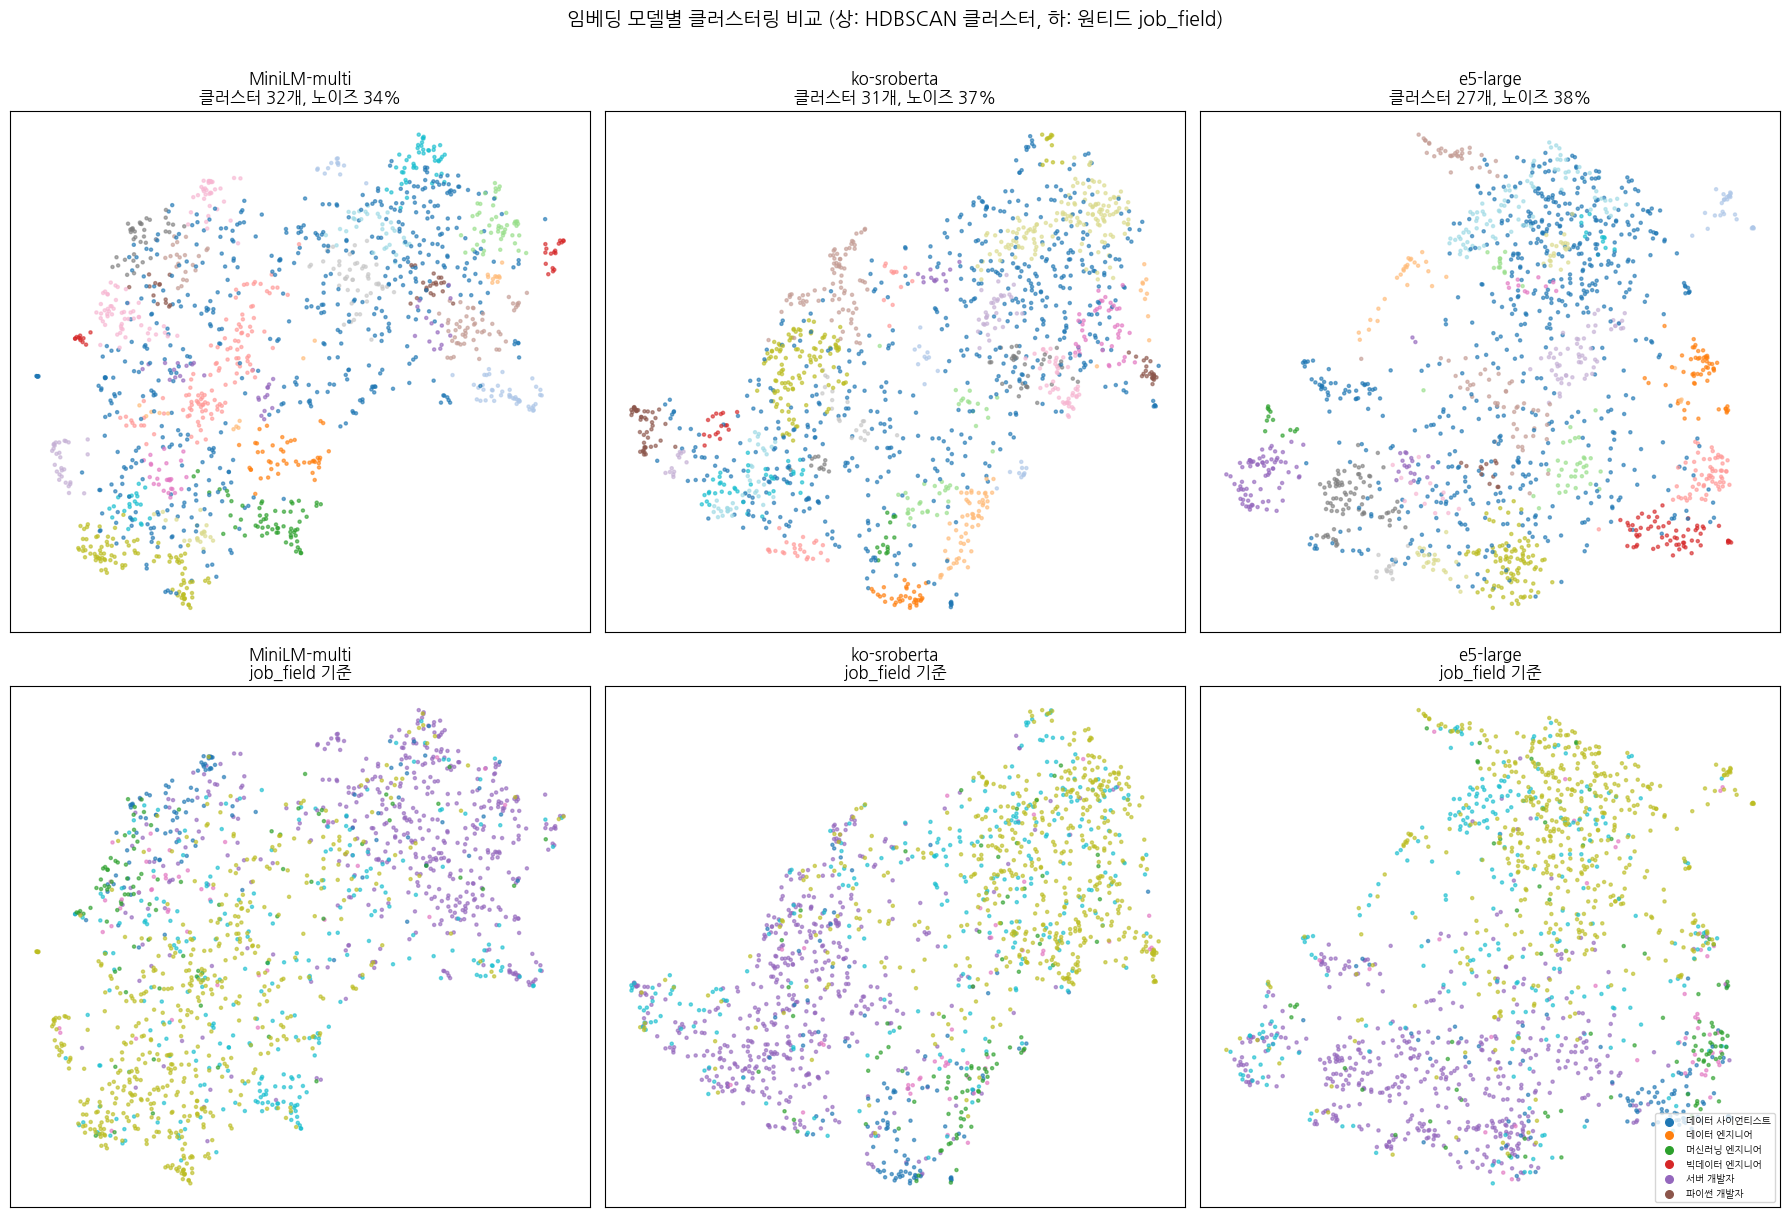

In [22]:
# 모델별 2D UMAP 시각화 비교 (클러스터 색상)
n_models = len(results)
fig, axes = plt.subplots(2, n_models, figsize=(6 * n_models, 12))

for col, (name, r) in enumerate(results.items()):
    # 상단: 클러스터 색상
    ax_top = axes[0, col] if n_models > 1 else axes[0]
    scatter = ax_top.scatter(
        r.umap_2d[:, 0], r.umap_2d[:, 1],
        c=r.cluster_labels, cmap='tab20', s=5, alpha=0.6
    )
    ax_top.set_title(f'{name}\n클러스터 {r.n_clusters}개, 노이즈 {r.noise_pct:.0%}')
    ax_top.set_xticks([]); ax_top.set_yticks([])
    
    # 하단: job_field 색상 (동일 좌표에 다른 색)
    ax_bot = axes[1, col] if n_models > 1 else axes[1]
    field_codes = job_fields.astype('category').cat.codes
    ax_bot.scatter(
        r.umap_2d[:, 0], r.umap_2d[:, 1],
        c=field_codes, cmap='tab10', s=5, alpha=0.6
    )
    ax_bot.set_title(f'{name}\njob_field 기준')
    ax_bot.set_xticks([]); ax_bot.set_yticks([])

# job_field 범례 (마지막 하단 축에)
ax_legend = axes[1, -1] if n_models > 1 else axes[1]
for i, field in enumerate(job_fields.astype('category').cat.categories):
    ax_legend.scatter([], [], c=[plt.cm.tab10(i / 10)], label=field, s=30)
ax_legend.legend(loc='lower right', fontsize=7)

plt.suptitle('임베딩 모델별 클러스터링 비교 (상: HDBSCAN 클러스터, 하: 원티드 job_field)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

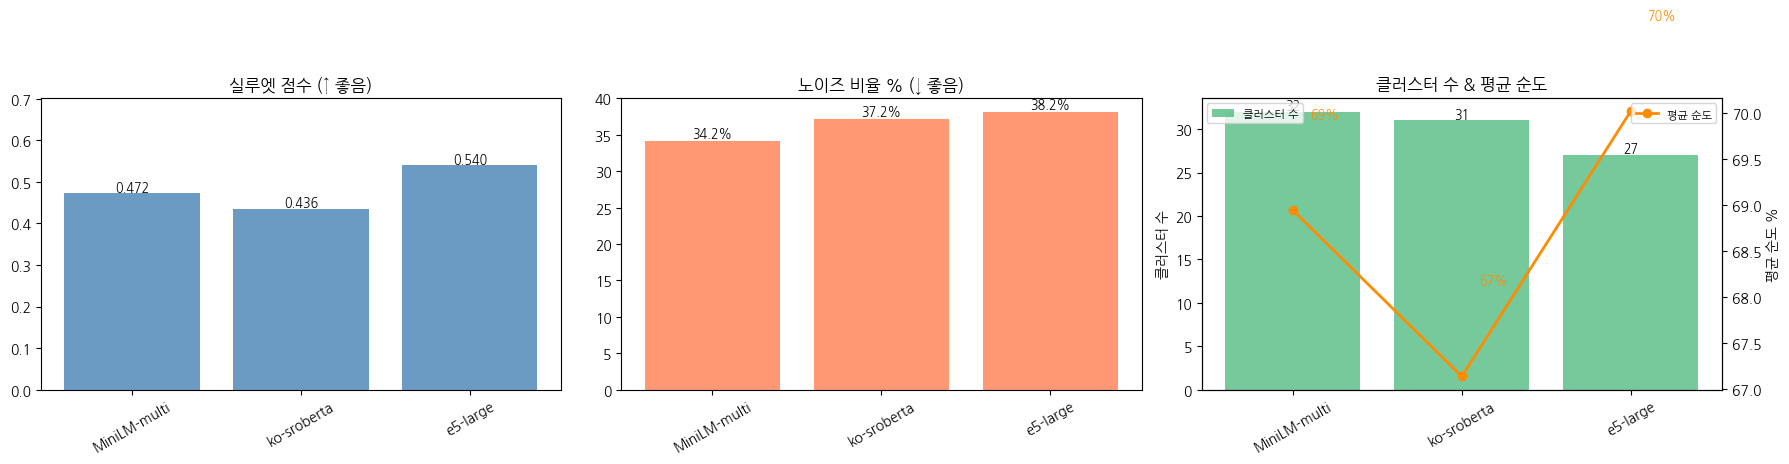

In [23]:
# 지표별 차트로 모델 종합 비교
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

names = list(results.keys())
x = range(len(names))

# 1) 실루엣 점수
sil_scores = [results[n].silhouette for n in names]
axes[0].bar(x, sil_scores, color='steelblue', alpha=0.8)
axes[0].set_xticks(x); axes[0].set_xticklabels(names, rotation=30)
axes[0].set_title('실루엣 점수 (↑ 좋음)')
axes[0].set_ylim(0, max(sil_scores) * 1.3 if max(sil_scores) > 0 else 1)
for i, v in enumerate(sil_scores):
    axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)

# 2) 노이즈 비율
noise_pcts = [results[n].noise_pct * 100 for n in names]
axes[1].bar(x, noise_pcts, color='coral', alpha=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels(names, rotation=30)
axes[1].set_title('노이즈 비율 % (↓ 좋음)')
for i, v in enumerate(noise_pcts):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)

# 3) 클러스터 수 + 평균 순도 (이중 축)
n_clusters_list = [results[n].n_clusters for n in names]
purities = [results[n].purity_mean * 100 for n in names]

ax3 = axes[2]
ax3.bar(x, n_clusters_list, color='mediumseagreen', alpha=0.7, label='클러스터 수')
ax3.set_xticks(x); ax3.set_xticklabels(names, rotation=30)
ax3.set_title('클러스터 수 & 평균 순도')
ax3.set_ylabel('클러스터 수')
for i, v in enumerate(n_clusters_list):
    ax3.text(i, v + 0.3, str(v), ha='center', fontsize=9)

ax3b = ax3.twinx()
ax3b.plot(x, purities, 'o-', color='darkorange', linewidth=2, label='평균 순도')
ax3b.set_ylabel('평균 순도 %')
for i, v in enumerate(purities):
    ax3b.text(i + 0.1, v + 1, f'{v:.0f}%', fontsize=9, color='darkorange')

ax3.legend(loc='upper left', fontsize=8)
ax3b.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

In [37]:
# 최적 모델 선택 → 이후 분석에 사용할 변수 설정
# ↓ 비교 결과를 보고 아래 BEST_MODEL을 변경
BEST_MODEL = 'e5-large'# 'MiniLM-multi'  # ← 비교 결과 보고 변경

best = results[BEST_MODEL]
embeddings = best.embeddings
df['cluster'] = best.cluster_labels
df['umap_x'] = best.umap_2d[:, 0]
df['umap_y'] = best.umap_2d[:, 1]

n_clusters = best.n_clusters

# 캐시 저장
import os
cache_dir = '../cache'
os.makedirs(cache_dir, exist_ok=True)
np.save(f'{cache_dir}/job_specialty_embeddings.npy', embeddings)
df[['id', 'position', 'job_field', 'combined_text']].to_csv(
    f'{cache_dir}/job_specialty_texts.csv', index=False
)

print(f"선택된 모델: {BEST_MODEL} ({best.model_name})")
print(f"  클러스터: {best.n_clusters}개, 노이즈: {best.noise_pct:.1%}")
print(f"  실루엣: {best.silhouette:.3f}, 평균순도: {best.purity_mean:.1%}")
print(f"  → 이후 섹션(4~8)은 이 모델의 결과로 분석됩니다")
print(f"  → 캐시 저장 완료: {cache_dir}/")

선택된 모델: e5-large (intfloat/multilingual-e5-large)
  클러스터: 27개, 노이즈: 38.2%
  실루엣: 0.540, 평균순도: 70.0%
  → 이후 섹션(4~8)은 이 모델의 결과로 분석됩니다
  → 캐시 저장 완료: ../cache/


## 4. 클러스터 해석: 대표 키워드 & 업무 패턴 추출

In [60]:
from sklearn.feature_extraction.text import TfidfVectorizer

def extract_cluster_keywords(df, cluster_col='cluster', text_col='combined_text', top_n=15):
    """
    각 클러스터의 TF-IDF 기반 대표 키워드 추출
    c-TF-IDF: 클러스터 내 문서를 하나로 합쳐서 전체 대비 특징적인 단어 추출
    """
    clusters = sorted(df[cluster_col].unique())
    clusters = [c for c in clusters if c != -1]  # 노이즈 제외
    
    # 클러스터별 텍스트 합치기
    cluster_texts = []
    for c in clusters:
        texts = df[df[cluster_col] == c][text_col].tolist()
        cluster_texts.append(' '.join(texts))
    
    # TF-IDF
    vectorizer = TfidfVectorizer(
        max_features=5000,
        token_pattern=r'(?u)[a-zA-Z가-힣][a-zA-Z가-힣.#+]+',  # 한글+영문, 기술명(.NET, C++) 허용
        stop_words=None,  # 한국어 불용어는 별도 처리
        min_df=1
    )
    
    tfidf_matrix = vectorizer.fit_transform(cluster_texts)
    feature_names = vectorizer.get_feature_names_out()
    
    # 불용어 (분석에 도움 안 되는 일반적인 단어)
    stopwords = {
        '경험', '이상', '우대', '관련', '개발', '업무', '경력', '능력',
        '이해', '기반', '활용', '환경', '기술', '서비스', '프로젝트',
        '가능', '역할', '수행', '담당', '필요', '보유', '사용',
        '분야', '협업', '문제', '해결', '작성', '설계', '구축',
        '운영', '지원', '참여', '진행', '등의', '및', '또는',
        '위한', '대한', '통한', '따른',
    }
    
    results = {}
    for i, c in enumerate(clusters):
        scores = tfidf_matrix[i].toarray().flatten()
        top_indices = scores.argsort()[::-1]
        
        keywords = []
        for idx in top_indices:
            word = feature_names[idx]
            if word not in stopwords and len(word) > 1:
                keywords.append((word, scores[idx]))
            if len(keywords) >= top_n:
                break
        
        results[c] = keywords
    
    return results


cluster_keywords = extract_cluster_keywords(df)

for cluster_id, keywords in cluster_keywords.items():
    size = (df['cluster'] == cluster_id).sum()
    top_positions = df[df['cluster'] == cluster_id]['position'].value_counts().head(5)
    top_fields = df[df['cluster'] == cluster_id]['job_field'].value_counts().head(3)
    
    print(f"\n{'='*80}")
    print(f"클러스터 {cluster_id} (n={size})")
    print(f"  주요 job_field: {', '.join(f'{f}({c})' for f, c in top_fields.items())}")
    print(f"  주요 position: {', '.join(f'{p}({c})' for p, c in top_positions.items())}")
    print(f"  대표 키워드: {', '.join(f'{w}' for w, s in keywords[:10])}")


클러스터 0 (n=42)
  주요 job_field: 머신러닝 엔지니어(26), 파이썬 개발자(8), 데이터 사이언티스트(3)
  주요 position: Data Scientist(2), 알고리즘 개발자(1), 인공지능 신약개발 연구원 (석사이상)(1), Computer Vision 개발자(1), Data Engineer(Healthcare)(1)
  대표 키워드: 의료, 데이터, 모델, ai, 연구, 의료용, 영상, 분석, 제어, 생체신호

클러스터 1 (n=27)
  주요 job_field: 서버 개발자(24), 빅데이터 엔지니어(2), 파이썬 개발자(1)
  주요 position: [프리랜서] 하나은행 SM 글로벌 통합정보 (중고급)(1), [프리랜서] 하나은행_글로벌 준법 시스템 SI(1), [프리랜서] 한화생명 융자 차세대 프로젝트_특급(1), [프리랜서] 증권 주식매매 시스템 개발 및 운영(1), [프리랜서] NH손보_ITO_콜시스템(고급)(1)
  대표 키워드: 근무기간, xplatform, 로직, oracle, 개월, 경험자, 관리, 계약, 필수스킬, 데이터

클러스터 2 (n=11)
  주요 job_field: 데이터 엔지니어(5), 데이터 사이언티스트(2), 빅데이터 엔지니어(2)
  주요 position: DBA(2), [웰컴페이먼츠] DBA 담당(3년 이상)(1), Cloud DBA(1), 데이터베이스 엔지니어(시니어)(1), PostgreSQL Technical Support Engineer(1)
  대표 키워드: 데이터베이스, 있는, 백업, db, 장애, 복구, ha, 있으신, 경험이, 성능

클러스터 3 (n=44)
  주요 job_field: 서버 개발자(23), 파이썬 개발자(9), 데이터 엔지니어(4)
  주요 position: DevOps Engineer(2), [TADA] Infra/DevOps Engineer(1), DevOps 엔지니어 (3년 이상)(1), AI Solutions Engineer(1), GPU 최적화 엔

In [62]:
# 클러스터별 상세 분석: 대표 공고 본문 샘플링
def show_cluster_samples(df, cluster_id, n=5):
    """클러스터 대표 공고의 주요업무/자격요건 출력"""
    cluster_df = df[df['cluster'] == cluster_id]
    samples = cluster_df.sample(min(n, len(cluster_df)), random_state=42)
    
    print(f"\n{'='*80}")
    print(f"클러스터 {cluster_id} 샘플 (총 {len(cluster_df)}건)")
    
    for _, row in samples.iterrows():
        print(f"\n  --- [{row['job_field']}] {row['position']} ---")
        if row['main_tasks']:
            print(f"  [주요업무] {row['main_tasks'][:200]}")
        if row['requirements']:
            print(f"  [자격요건] {row['requirements'][:200]}")

# 주요 클러스터 샘플 확인 (상위 5개)
top_clusters = df[df['cluster'] != -1]['cluster'].value_counts().head(5).index
for c in top_clusters:
    show_cluster_samples(df, c)


클러스터 21 샘플 (총 96건)

  --- [파이썬 개발자] AI Agent 백엔드 개발자 (3년 이상) ---
  [주요업무] 1. 벡터 기반 Database 설계 및 구축 • 비정형 데이터 체계화, 멀티모달 검색을 고려한 Database 설계  • Hybrid (Vector + Keyword) 검색을 지원할 수 있는 DB 구축• 멀티모달 문서(텍스트, 표, 이미지) 기반 검색 확장 설계2. 비정형 데이터 메타데이터 설계• 도메인 특성을 고려한 Chunk 전략 수립• 멀티 모달을 
  [자격요건] • RAG를 활용한 AI Agent 서비스 개발 및 운영 경험 • 여러 자료를 벡터 기반 DB로 설계 및 구축 경험• 표, 이미지, 텍스트 등 멀티모달 검색을 위한 문서 청킹 경험 • 복잡한 비정형 데이터를 파싱해서 체계적이고 구조화된 메타데이터 설계가 가능한 분• Advanced RAG 를 위한 데이터베이스 설계 경험 있으신 분• Python 기반 백엔드

  --- [파이썬 개발자] [EC솔루션연구소] AI 기술 개발자 (전문연구요원 현역) ---
  [주요업무] 1. 생성형 AI 및 머신러닝 이론 이해 1) 머신러닝 / 딥러닝 기초 ① 머신러닝 기본 개념 이해    - 지도학습 / 비지도학습    - 모델 평가 ② 딥러닝 기본 구조 이해     - CNN / RNN / Attention 구조 ③ Transformer 기반 모델 구조 이해    - self-attention    - encoder / decoder 
  [자격요건] 1) 전문연구요원(현역) 자격을 갖춘 자(※ 전직 불가) 2) 관련분야 석사 이상 학위 취득자   - NLP(자연어 처리) 분야   - 딥러닝 분야 3) 관련 기술 보유자 • 프로그래밍 기초 소양    - Python, TypeScript + JavasScript(Node.js, React, Svelte), Rust언어 응용    - OOP, 함수형 코딩,

  --- [데이터 사이언티스트] AI 관련 PM(Project Man

### 4.1 클러스터 간 차별 키워드 분석

클러스터 내 키워드가 아니라, "이 클러스터에는 있지만 다른 클러스터에는 없는" 키워드를 추출.
이게 있어야 클러스터 간 경계가 명확해지고, 직무 분류 기준을 정의할 수 있다.

In [63]:
# 클러스터 간 차별 키워드 (노이즈 제외)
df_clustered = df[df['cluster'] != -1].copy()
disc_keywords = get_discriminative_keywords(df_clustered, 'cluster', top_n=10)

# 주요 클러스터(크기 상위 10개)만 출력
top_10_clusters = df_clustered['cluster'].value_counts().head(10).index

for c in sorted(top_10_clusters):
    size = (df_clustered['cluster'] == c).sum()
    top_field = df_clustered[df_clustered['cluster'] == c]['job_field'].value_counts().index[0]
    top_pos = df_clustered[df_clustered['cluster'] == c]['position'].value_counts().head(3)
    keywords = disc_keywords.get(c, [])
    
    print(f"\n{'='*80}")
    print(f"클러스터 {c} (n={size}) | 주요 job_field: {top_field}")
    print(f"  빈출 position: {', '.join(f'{p}({n})' for p, n in top_pos.items())}")
    print(f"  차별 키워드 (이 클러스터에서만 특히 많이 등장):")
    for word, tfidf, disc in keywords[:8]:
        bar = '█' * int(min(disc, 30))
        print(f"    {word:20s}  {disc:5.1f}x  {bar}")


클러스터 0 (n=42) | 주요 job_field: 머신러닝 엔지니어
  빈출 position: Data Scientist(2), 알고리즘 개발자(1), 인공지능 신약개발 연구원 (석사이상)(1)
  차별 키워드 (이 클러스터에서만 특히 많이 등장):
    마스터                   100.0x  ██████████████████████████████
    생체신호                  100.0x  ██████████████████████████████
    mfds                  100.0x  ██████████████████████████████
    qt                    100.0x  ██████████████████████████████
    ct                    100.0x  ██████████████████████████████
    loinc                 100.0x  ██████████████████████████████
    약물상호작용                100.0x  ██████████████████████████████
    영상품질                  100.0x  ██████████████████████████████

클러스터 3 (n=44) | 주요 job_field: 서버 개발자
  빈출 position: DevOps Engineer(2), [TADA] Infra/DevOps Engineer(1), DevOps 엔지니어 (3년 이상)(1)
  차별 키워드 (이 클러스터에서만 특히 많이 등장):
    성장해요                  100.0x  ██████████████████████████████
    목요일                   100.0x  ██████████████████████████████
    국가보훈대상자               100.0x  █████████████

### 4.2 Position 제목 패턴 vs 본문 클러스터 교차 검증

제목에 "백엔드", "데이터", "AI" 등이 들어간 공고가 실제로 같은 클러스터에 모이는지 확인.
제목-본문 불일치 케이스는 회사가 부정확한 제목을 쓴 것이거나, 경계에 걸친 직무.

In [64]:
# 제목에서 직무 키워드 추출
import re

def extract_title_role(position: str) -> str:
    """position 제목에서 직무 계열 키워드 추출"""
    pos_lower = position.lower()
    
    patterns = {
        '백엔드/서버': r'backend|back-end|백엔드|서버|server',
        '프론트엔드': r'frontend|front-end|프론트엔드|web\s*developer',
        '풀스택': r'fullstack|full-stack|full\s*stack|풀스택',
        'AI/ML': r'\bai\b|machine\s*learning|머신러닝|딥러닝|deep\s*learning|\bml\b|\bllm\b',
        '데이터 엔지니어': r'data\s*engineer|데이터\s*엔지니어|빅데이터|big\s*data',
        '데이터 분석': r'data\s*analyst|데이터\s*분석|비즈니스\s*분석|analytics',
        '데이터 사이언스': r'data\s*scien|데이터\s*사이언|리서치|research',
        'MLOps/인프라': r'mlops|devops|infra|인프라|sre|platform',
        '임베디드/시스템': r'embedded|임베디드|시스템\s*sw|system\s*sw|firmware',
        'CV/비전': r'computer\s*vision|vision|비전|영상|이미지|image',
        'NLP/언어': r'\bnlp\b|자연어|natural\s*language|language\s*model',
    }
    
    matched = []
    for role, pattern in patterns.items():
        if re.search(pattern, pos_lower):
            matched.append(role)
    
    return matched[0] if len(matched) == 1 else ('복합' if matched else '기타')

df['title_role'] = df['position'].apply(extract_title_role)

print("제목 기반 직무 분류 분포:")
print(df['title_role'].value_counts())
print(f"\n'기타' 비율: {(df['title_role'] == '기타').mean():.1%}")

제목 기반 직무 분류 분포:
title_role
백엔드/서버       388
기타           351
AI/ML        308
복합           173
데이터 엔지니어      70
풀스택           64
데이터 사이언스      48
MLOps/인프라     42
데이터 분석        34
CV/비전         17
임베디드/시스템       4
프론트엔드          4
NLP/언어         1
Name: count, dtype: int64

'기타' 비율: 23.3%


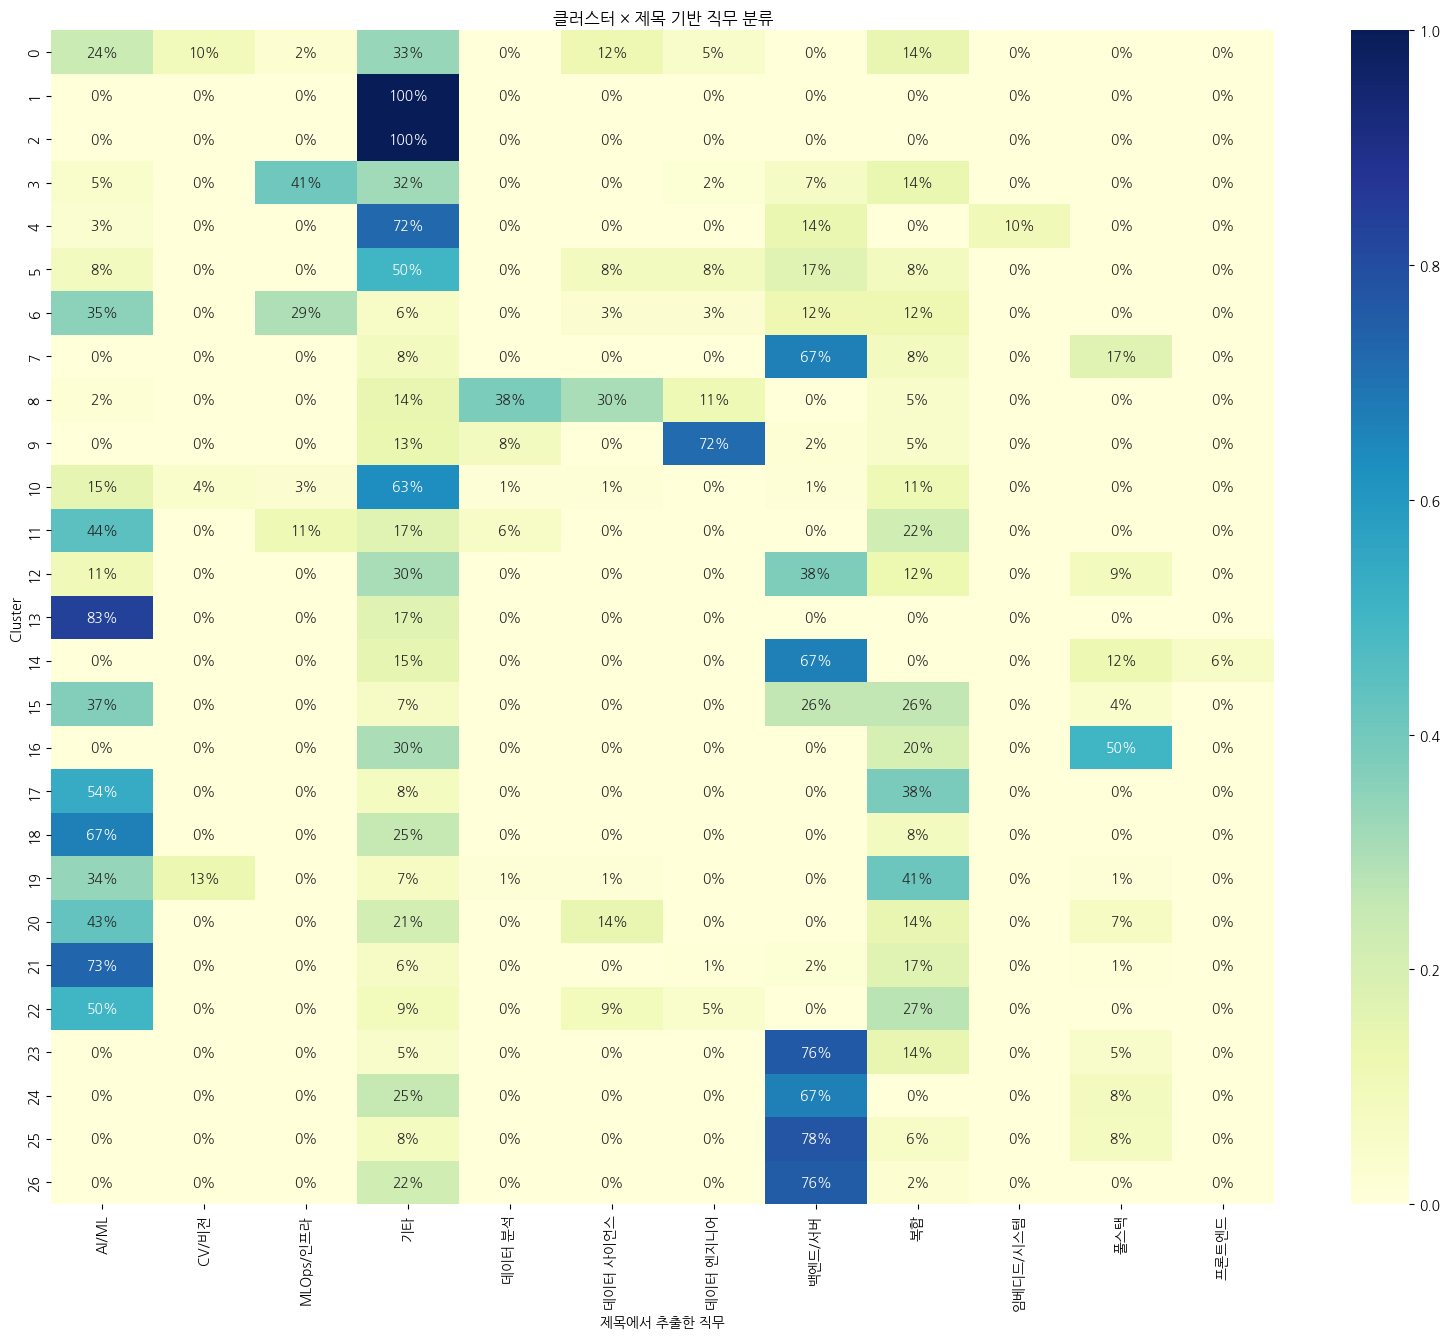

In [65]:
# 제목 직무 vs 클러스터 교차표
ct_title = pd.crosstab(
    df[df['cluster'] != -1]['cluster'],
    df[df['cluster'] != -1]['title_role'],
    margins=True
)

# 히트맵: 클러스터별 title_role 비율
ct_title_no_margin = ct_title.drop('All', axis=0).drop('All', axis=1)
ct_title_pct = ct_title_no_margin.div(ct_title_no_margin.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(16, max(8, n_clusters * 0.5)))
sns.heatmap(
    ct_title_pct, annot=True, fmt='.0%', cmap='YlGnBu',
    xticklabels=True, yticklabels=True, ax=ax
)
ax.set_title('클러스터 × 제목 기반 직무 분류')
ax.set_ylabel('Cluster')
ax.set_xlabel('제목에서 추출한 직무')
plt.tight_layout()
plt.show()

In [66]:
# 제목-본문 불일치 분석: 제목의 직무와 클러스터 다수 직무가 다른 케이스
# df_clustered에 title_role 반영 (df에서 생성된 컬럼)
df_clustered['title_role'] = df.loc[df['cluster'] != -1, 'title_role'].values

print("제목-본문 불일치 의심 케이스:")
print("(제목에서 추출한 직무 ≠ 해당 클러스터의 다수 제목 직무)\n")

mismatch_count = 0
for c in sorted(df_clustered['cluster'].unique()):
    cluster_df = df_clustered[df_clustered['cluster'] == c]
    dominant_title_role = cluster_df['title_role'].value_counts().index[0]
    
    # 클러스터 다수 직무와 다른 공고 찾기
    mismatches = cluster_df[
        (cluster_df['title_role'] != dominant_title_role) & 
        (cluster_df['title_role'] != '기타') &
        (cluster_df['title_role'] != '복합')
    ]
    
    if len(mismatches) > 0:
        for _, row in mismatches.head(3).iterrows():
            print(f"  클러스터 {c} (다수: {dominant_title_role}) ← [{row['title_role']}] {row['position']}")
            mismatch_count += 1

print(f"\n총 불일치 케이스: {mismatch_count}건")
print("→ 이 케이스들은 회사가 부정확한 제목을 쓴 것이거나, 직무 경계가 모호한 공고")

제목-본문 불일치 의심 케이스:
(제목에서 추출한 직무 ≠ 해당 클러스터의 다수 제목 직무)

  클러스터 0 (다수: 기타) ← [CV/비전] Computer Vision 개발자
  클러스터 0 (다수: 기타) ← [데이터 엔지니어] Data Engineer(Healthcare)
  클러스터 0 (다수: 기타) ← [AI/ML] AI 기반 헬스케어 개발자
  클러스터 3 (다수: MLOps/인프라) ← [AI/ML] AI Solutions Engineer
  클러스터 3 (다수: MLOps/인프라) ← [데이터 엔지니어] 빅데이터 시스템 구축 및 운영 담당자(2년 이상)
  클러스터 3 (다수: MLOps/인프라) ← [AI/ML] Kubernetes 에이전트 개발자 (GPU/AI Observability)
  클러스터 4 (다수: 기타) ← [백엔드/서버] 백엔드/서버 개발자
  클러스터 4 (다수: 기타) ← [임베디드/시스템] Embedded Linux SW Engineer
  클러스터 4 (다수: 기타) ← [AI/ML] AI Robotics Field Application Engineer
  클러스터 5 (다수: 기타) ← [AI/ML] Sr. Deep Learning Algorithm Engineer
  클러스터 5 (다수: 기타) ← [데이터 사이언스] Research Engineer - Vison Foundation Models
  클러스터 5 (다수: 기타) ← [백엔드/서버] Backend Engineer (Data Service Team)
  클러스터 6 (다수: AI/ML) ← [MLOps/인프라] Forward Deployed Engineer - MLOps
  클러스터 6 (다수: AI/ML) ← [MLOps/인프라] [R&D파트] MLOps 엔지니어
  클러스터 6 (다수: AI/ML) ← [MLOps/인프라] MLOps Engineer
  클러스터 7 (다수: 백엔드/서버) ← [풀스택] Software Engineer, Full 

## 5. 클러스터 ↔ job_field 교차 분석

원티드의 job_field 분류와 데이터 기반 클러스터가 얼마나 일치/불일치하는지 확인.
불일치가 크면 → 원티드 분류가 실제 업무와 안 맞는 영역.

In [67]:
# 교차표 (클러스터 × job_field)
ct = pd.crosstab(
    df[df['cluster'] != -1]['cluster'],
    df[df['cluster'] != -1]['job_field'],
    margins=True
)

print("클러스터 × job_field 교차표:")
ct

클러스터 × job_field 교차표:


job_field,데이터 사이언티스트,데이터 엔지니어,머신러닝 엔지니어,빅데이터 엔지니어,서버 개발자,파이썬 개발자,All
cluster,,,,,,,
0,3,0,26,2,3,8,42
1,0,0,0,2,24,1,27
2,2,5,0,2,0,2,11
3,1,4,3,4,23,9,44
4,0,0,0,0,18,11,29
5,0,3,4,0,3,2,12
6,1,1,24,1,4,3,34
7,0,2,1,0,6,3,12
8,48,6,6,0,0,3,63


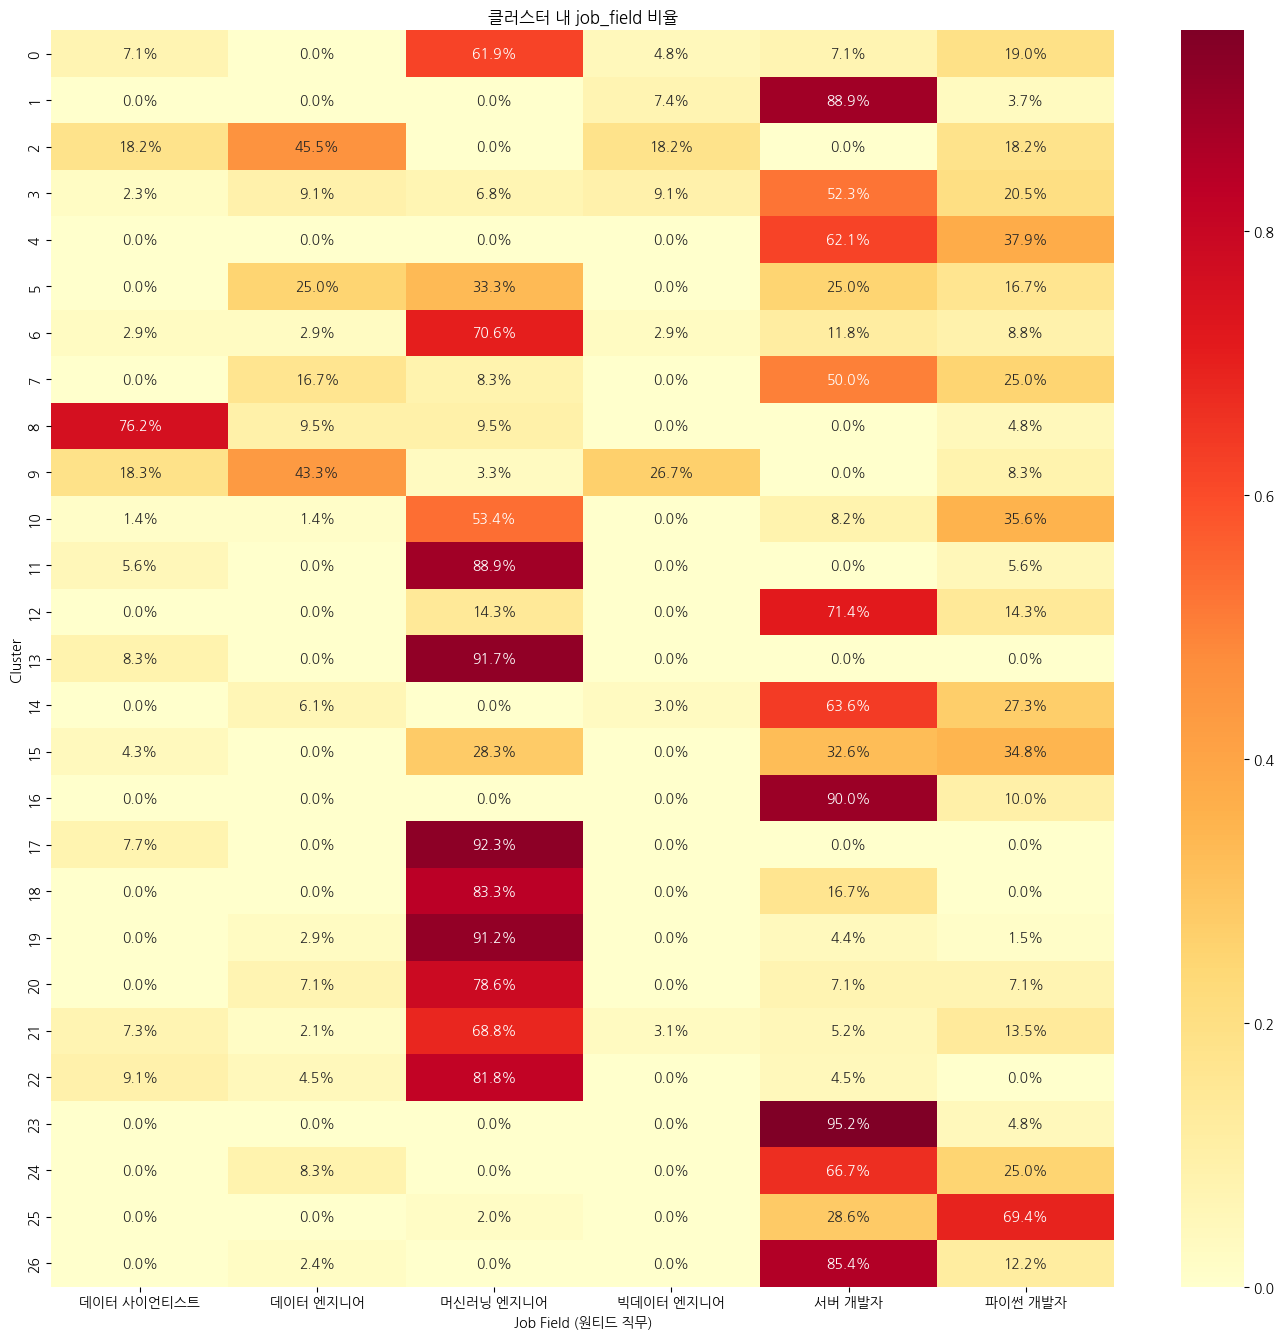

In [68]:
# 히트맵 시각화
ct_no_margin = ct.drop('All', axis=0).drop('All', axis=1)

# 비율로 변환 (행 기준 = 클러스터 내 job_field 비율)
ct_pct = ct_no_margin.div(ct_no_margin.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(14, max(8, n_clusters * 0.5)))
sns.heatmap(
    ct_pct, annot=True, fmt='.1%', cmap='YlOrRd',
    xticklabels=True, yticklabels=True, ax=ax
)
ax.set_title('클러스터 내 job_field 비율')
ax.set_ylabel('Cluster')
ax.set_xlabel('Job Field (원티드 직무)')
plt.tight_layout()
plt.show()

In [69]:
# 클러스터 순도 분석: 각 클러스터가 얼마나 하나의 job_field에 집중되는지
purity_scores = []
for c in sorted(df[df['cluster'] != -1]['cluster'].unique()):
    cluster_df = df[df['cluster'] == c]
    dominant_field = cluster_df['job_field'].value_counts().iloc[0]
    purity = dominant_field / len(cluster_df)
    dominant_name = cluster_df['job_field'].value_counts().index[0]
    purity_scores.append({
        'cluster': c,
        'size': len(cluster_df),
        'dominant_field': dominant_name,
        'purity': purity
    })

purity_df = pd.DataFrame(purity_scores)
print(f"평균 순도: {purity_df['purity'].mean():.2%}")
print(f"\n클러스터별 순도:")
purity_df.sort_values('purity', ascending=False)

평균 순도: 70.02%

클러스터별 순도:


,cluster,size,dominant_field,purity
23,23,21,서버 개발자,0.952381
17,17,13,머신러닝 엔지니어,0.923077
13,13,12,머신러닝 엔지니어,0.916667
19,19,68,머신러닝 엔지니어,0.911765
16,16,10,서버 개발자,0.900000
11,11,18,머신러닝 엔지니어,0.888889
1,1,27,서버 개발자,0.888889
26,26,41,서버 개발자,0.853659
18,18,12,머신러닝 엔지니어,0.833333
22,22,22,머신러닝 엔지니어,0.818182


## 5.5 계층적 클러스터링: 큰 그룹 → 세분화

HDBSCAN은 밀도 기반으로 27개의 세부 클러스터를 생성했지만, 이걸 바로 직무명으로 매핑하기엔 너무 많다.
그래서 2단계 접근을 사용한다:

1. **클러스터 중심(centroid) 계산**: 각 HDBSCAN 클러스터에 속한 공고들의 임베딩 평균 벡터를 구한다.
2. **클러스터 간 거리 측정**: 27개 centroid 사이의 코사인 거리를 계산한다.
3. **계층적 클러스터링(Ward linkage)**: centroid 간 거리로 덴드로그램을 만든다.
   → 가까운 클러스터끼리 단계적으로 합쳐지는 트리 구조가 생긴다.
4. **덴드로그램을 적절한 높이에서 자르기**: 3~6개 수준으로 잘라서 L1 대분류를 도출한다.

이렇게 하면 HDBSCAN의 세밀한 분리 능력은 유지하면서, 해석 가능한 수준의 대분류 체계를 얻을 수 있다.

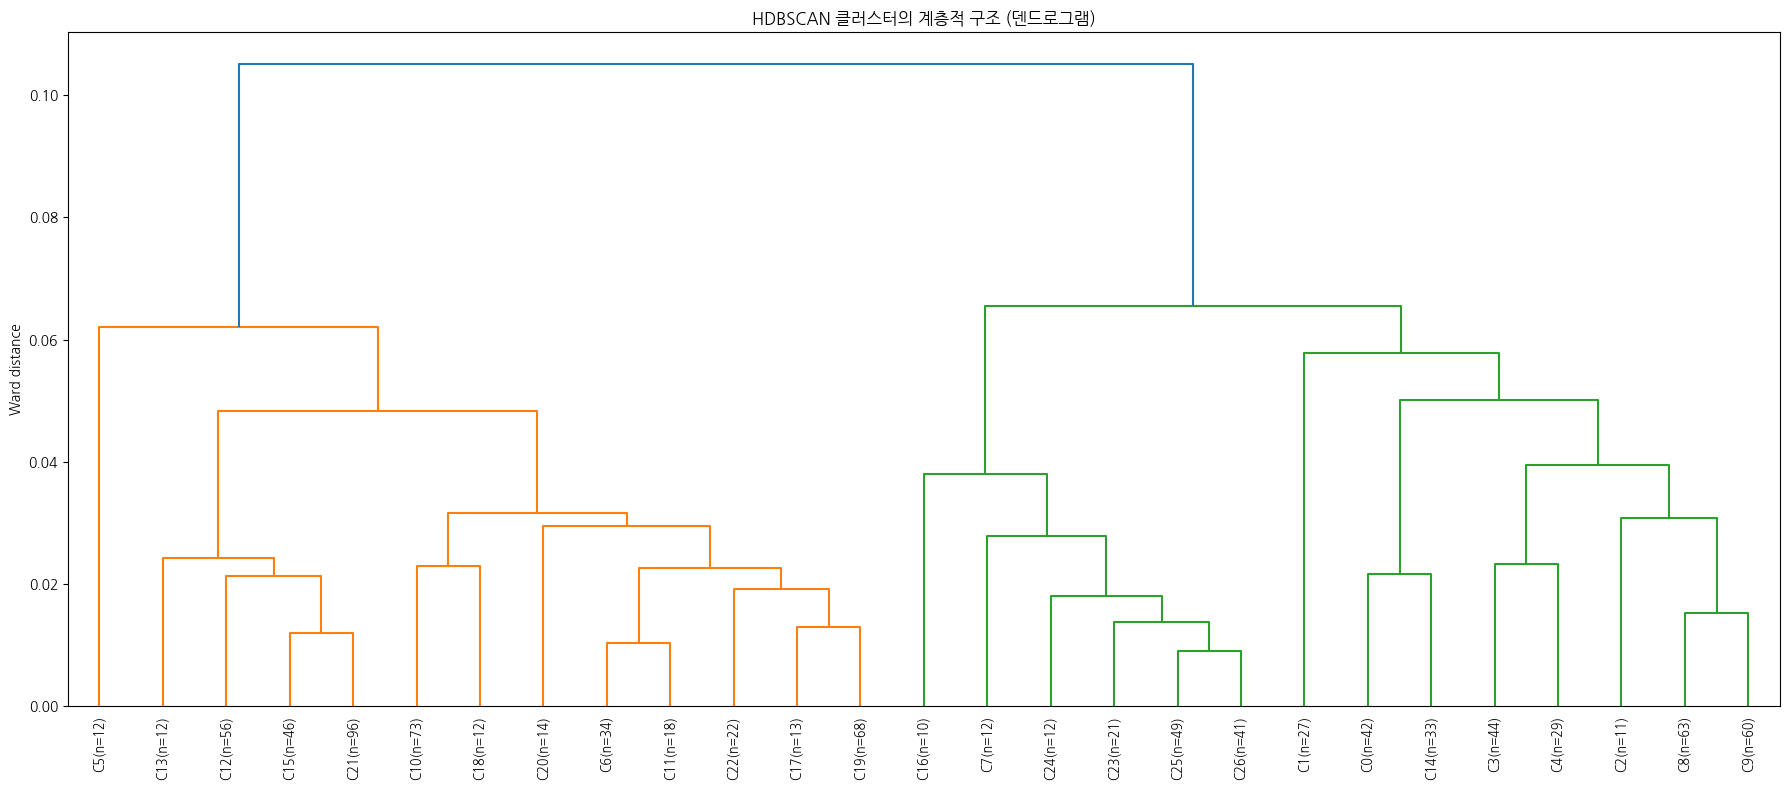

덴드로그램에서 큰 가지를 자르면 L1 대분류가 됨


In [70]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.metrics.pairwise import cosine_similarity

# 클러스터 중심(centroid) 계산 (노이즈 제외)
cluster_ids = sorted(df_clustered['cluster'].unique())
centroids = []
for c in cluster_ids:
    mask = df_clustered['cluster'] == c
    centroid = embeddings[df['cluster'] == c].mean(axis=0)
    centroids.append(centroid)

centroids = np.array(centroids)

# 클러스터 간 거리 → 계층적 클러스터링
from scipy.spatial.distance import pdist
dist_matrix = pdist(centroids, metric='cosine')
Z = linkage(dist_matrix, method='ward')

# 덴드로그램
fig, ax = plt.subplots(figsize=(18, 8))
dendrogram(
    Z,
    labels=[f"C{c}(n={int((df_clustered['cluster']==c).sum())})" for c in cluster_ids],
    leaf_rotation=90,
    leaf_font_size=9,
    ax=ax
)
ax.set_title('HDBSCAN 클러스터의 계층적 구조 (덴드로그램)')
ax.set_ylabel('Ward distance')
plt.tight_layout()
plt.show()

print("덴드로그램에서 큰 가지를 자르면 L1 대분류가 됨")

In [77]:
# L1 대분류: 덴드로그램을 적절한 높이에서 자르기 (3~6개 그룹)
for n_groups in [3, 4, 5, 6]:
    l1_labels = fcluster(Z, t=n_groups, criterion='maxclust')
    
    # HDBSCAN 클러스터 → L1 매핑
    cluster_to_l1 = {c: l1 for c, l1 in zip(cluster_ids, l1_labels)}
    df_clustered[f'l1_{n_groups}'] = df_clustered['cluster'].map(cluster_to_l1)
    
    print(f"\n{'='*60}")
    print(f"L1 = {n_groups}개 그룹")
    for l1 in sorted(df_clustered[f'l1_{n_groups}'].unique()):
        l1_df = df_clustered[df_clustered[f'l1_{n_groups}'] == l1]
        clusters_in = sorted(l1_df['cluster'].unique())
        top_title = l1_df['title_role'].value_counts().head(3)
        top_field = l1_df['job_field'].value_counts().head(2)
        print(f"\n  L1-{l1} ({len(l1_df)}건) | 클러스터: {clusters_in}")
        print(f"    제목 직무: {', '.join(f'{r}({n})' for r, n in top_title.items())}")
        print(f"    원티드 직무: {', '.join(f'{f}({n})' for f, n in top_field.items())}")


L1 = 3개 그룹

  L1-1 (476건) | 클러스터: [np.int64(5), np.int64(6), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]
    제목 직무: AI/ML(190), 기타(99), 복합(94)
    원티드 직무: 머신러닝 엔지니어(294), 서버 개발자(80)

  L1-2 (145건) | 클러스터: [np.int64(7), np.int64(16), np.int64(23), np.int64(24), np.int64(25), np.int64(26)]
    제목 직무: 백엔드/서버(101), 기타(21), 풀스택(13)
    원티드 직무: 서버 개발자(92), 파이썬 개발자(47)

  L1-3 (309건) | 클러스터: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(8), np.int64(9), np.int64(14)]
    제목 직무: 기타(109), 데이터 엔지니어(53), 백엔드/서버(30)
    원티드 직무: 서버 개발자(89), 데이터 사이언티스트(65)

L1 = 4개 그룹

  L1-1 (464건) | 클러스터: [np.int64(6), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]
    제목 직무: AI/ML(189), 기타(93), 복합(93)
    원티드 직무: 머신러닝 엔지니어(290), 서버 개발자(77)

  L1-2 (12건) | 클러스터: [np.int64

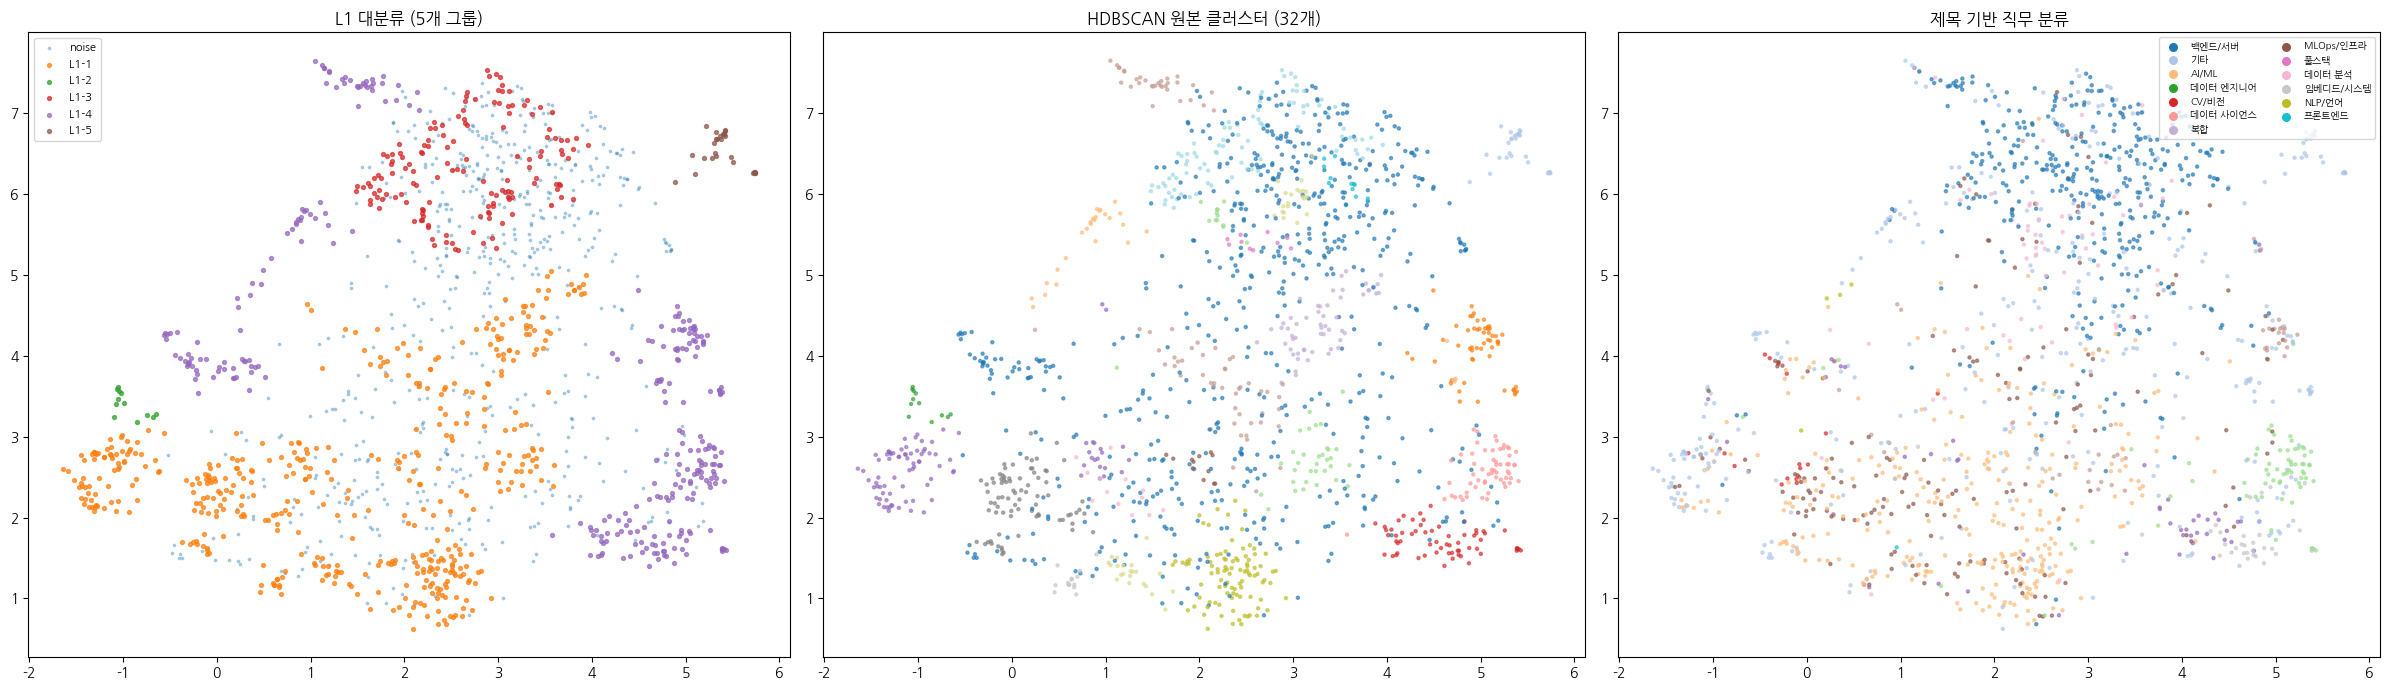

In [78]:
# 최적 L1 그룹 수 선택 후, 2D UMAP에 L1 대분류 시각화
# ↓ 위 결과를 보고 적절한 n_groups를 선택 (기본 5로 설정, 필요시 변경)
BEST_N_GROUPS = 5

l1_labels_best = fcluster(Z, t=BEST_N_GROUPS, criterion='maxclust')
cluster_to_l1_best = {c: l1 for c, l1 in zip(cluster_ids, l1_labels_best)}
df['l1_group'] = df['cluster'].map(cluster_to_l1_best).fillna(-1).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

# 1) L1 대분류
for l1 in sorted(df['l1_group'].unique()):
    mask = df['l1_group'] == l1
    label = f'L1-{l1}' if l1 != -1 else 'noise'
    alpha = 0.3 if l1 == -1 else 0.7
    s = 3 if l1 == -1 else 8
    axes[0].scatter(df.loc[mask, 'umap_x'], df.loc[mask, 'umap_y'],
                    s=s, alpha=alpha, label=label)
axes[0].set_title(f'L1 대분류 ({BEST_N_GROUPS}개 그룹)')
axes[0].legend(fontsize=8)

# 2) HDBSCAN 원본 클러스터 (비교용)
scatter = axes[1].scatter(
    df['umap_x'], df['umap_y'],
    c=df['cluster'], cmap='tab20', s=5, alpha=0.6
)
axes[1].set_title('HDBSCAN 원본 클러스터 (32개)')

# 3) 제목 기반 직무 (비교용)
title_roles = df['title_role'].unique()
role_colors = {r: i for i, r in enumerate(title_roles)}
axes[2].scatter(
    df['umap_x'], df['umap_y'],
    c=df['title_role'].map(role_colors), cmap='tab20', s=5, alpha=0.6
)
for role, ci in role_colors.items():
    axes[2].scatter([], [], c=[plt.cm.tab20(ci / len(role_colors))], label=role, s=30)
axes[2].set_title('제목 기반 직무 분류')
axes[2].legend(fontsize=7, ncol=2, loc='upper right')

plt.tight_layout()
plt.show()

In [79]:
# L1 대분류별 차별 키워드 → 대분류 이름 짓기
l1_keywords = get_discriminative_keywords(
    df[df['l1_group'] != -1], 'l1_group', top_n=12
)

for l1, keywords in l1_keywords.items():
    l1_df = df[df['l1_group'] == l1]
    top_title = l1_df['title_role'].value_counts().head(3)
    top_field = l1_df['job_field'].value_counts().head(3)
    top_pos = l1_df['position'].value_counts().head(5)
    
    print(f"\n{'='*80}")
    print(f"L1-{l1} ({len(l1_df)}건)")
    print(f"  제목 직무: {', '.join(f'{r}({n})' for r, n in top_title.items())}")
    print(f"  원티드 직무: {', '.join(f'{f}({n})' for f, n in top_field.items())}")
    print(f"  빈출 position:")
    for p, n in top_pos.items():
        print(f"    - {p} ({n}건)")
    print(f"  차별 키워드:")
    for word, tfidf, disc in keywords[:10]:
        bar = '█' * int(min(disc, 20))
        print(f"    {word:20s}  {disc:5.1f}x  {bar}")
    print(f"\n  → 제안 대분류명: ???  (위 정보를 보고 직접 판단)")


L1-1 (464건)
  제목 직무: AI/ML(189), 기타(93), 복합(93)
  원티드 직무: 머신러닝 엔지니어(290), 서버 개발자(77), 파이썬 개발자(69)
  빈출 position:
    - AI 엔지니어 (6건)
    - AI Agent Engineer (6건)
    - Backend Engineer (4건)
    - AI Research Engineer (4건)
    - AI Engineer (4건)
  차별 키워드:
    use                   100.0x  ████████████████████
    파인튜닝                  100.0x  ████████████████████
    vlm                   100.0x  ████████████████████
    prompt                100.0x  ████████████████████
    calling               100.0x  ████████████████████
    isaac                 100.0x  ████████████████████
    sim                   100.0x  ████████████████████
    강화학습                  100.0x  ████████████████████
    cv                    100.0x  ████████████████████
    slam                  100.0x  ████████████████████

  → 제안 대분류명: ???  (위 정보를 보고 직접 판단)

L1-2 (12건)
  제목 직무: 기타(6), 백엔드/서버(2), AI/ML(1)
  원티드 직무: 머신러닝 엔지니어(4), 데이터 엔지니어(3), 서버 개발자(3)
  빈출 position:
    - Sr. Deep Learning Algorithm Engineer (1건)
 

## 6. 노이즈(-1) 분석

HDBSCAN이 클러스터에 넣지 못한 공고들. 
독특한 직무이거나 여러 직무 경계에 걸친 공고일 수 있음.

In [81]:
noise_df = df[df['cluster'] == -1]
print(f"노이즈 공고 수: {len(noise_df)} ({len(noise_df)/len(df)*100:.1f}%)")
print(f"\n노이즈 공고의 job_field 분포:")
print(noise_df['job_field'].value_counts())
print(f"\n노이즈 공고의 position 샘플 (20개):")
print(noise_df['position'].sample(min(20, len(noise_df)), random_state=42).tolist())

노이즈 공고 수: 574 (38.2%)

노이즈 공고의 job_field 분포:
job_field
서버 개발자        256
머신러닝 엔지니어     149
파이썬 개발자       102
데이터 엔지니어       32
데이터 사이언티스트     23
빅데이터 엔지니어      12
Name: count, dtype: int64

노이즈 공고의 position 샘플 (20개):
['Backend Engineer (Nodejs, Java, Kotlin)', '[제품 본부] AI Engineer - 3년 이상 (전문연구요원 가능)', '백엔드 개발자', '앱 개발자 (React Native,  2년 이상)', 'Backend Engineer (Connected Service)', 'AI 엔지니어', '[더운반] Data Scientist 5년 이상', 'Data Scientist', 'ML Research Engineer (Vision & Scalability)', 'AI Engineer (시니어)', 'Product Dev. Team Lead', '백엔드 개발자(Backend Engineer)', '백엔드, 프론트 개발자 (Python, Django, Vue)(1년 이상)', 'AI SDK Engineer', 'LOST ARK Mobile 서버개발 담당', '생성형 AI 데이터 사이언티스트', '[강남] AI연구소 백엔드 개발', 'LLM Engineer (Reinforcement Learning)', 'ML Engineer', '게임 백엔드 개발자(5년 이상)']


## 7. Taxonomy 초안 도출

클러스터 분석 결과를 바탕으로 job_specialty 분류 체계 초안을 정리한다.
각 클러스터에 의미 있는 직무명을 부여하고, 판별 기준(키워드, 업무 패턴)을 정리.

In [82]:
# 클러스터별 종합 정보 정리
taxonomy_draft = []

for cluster_id in sorted(df[df['cluster'] != -1]['cluster'].unique()):
    cluster_df = df[df['cluster'] == cluster_id]
    keywords = cluster_keywords.get(cluster_id, [])
    
    entry = {
        'cluster_id': cluster_id,
        'size': len(cluster_df),
        'top_positions': cluster_df['position'].value_counts().head(5).to_dict(),
        'job_field_dist': cluster_df['job_field'].value_counts().to_dict(),
        'top_keywords': [w for w, s in keywords[:10]],
        'suggested_name': '???',  # 수동으로 채울 부분
    }
    taxonomy_draft.append(entry)

# 보기 좋게 출력
for entry in taxonomy_draft:
    print(f"\n{'='*80}")
    print(f"클러스터 {entry['cluster_id']} | 크기: {entry['size']}건 | 제안 직무명: {entry['suggested_name']}")
    print(f"  job_field 분포: {entry['job_field_dist']}")
    print(f"  대표 키워드: {', '.join(entry['top_keywords'])}")
    print(f"  빈출 position:")
    for pos, cnt in entry['top_positions'].items():
        print(f"    - {pos} ({cnt}건)")


클러스터 0 | 크기: 42건 | 제안 직무명: ???
  job_field 분포: {'머신러닝 엔지니어': 26, '파이썬 개발자': 8, '데이터 사이언티스트': 3, '서버 개발자': 3, '빅데이터 엔지니어': 2}
  대표 키워드: 의료, 데이터, 모델, ai, 연구, 의료용, 영상, 분석, 제어, 생체신호
  빈출 position:
    - Data Scientist (2건)
    - 알고리즘 개발자 (1건)
    - 인공지능 신약개발 연구원 (석사이상) (1건)
    - Computer Vision 개발자 (1건)
    - Data Engineer(Healthcare) (1건)

클러스터 1 | 크기: 27건 | 제안 직무명: ???
  job_field 분포: {'서버 개발자': 24, '빅데이터 엔지니어': 2, '파이썬 개발자': 1}
  대표 키워드: 근무기간, xplatform, 로직, oracle, 개월, 경험자, 관리, 계약, 필수스킬, 데이터
  빈출 position:
    - [프리랜서] 하나은행 SM 글로벌 통합정보 (중고급) (1건)
    - [프리랜서] 하나은행_글로벌 준법 시스템 SI (1건)
    - [프리랜서] 한화생명 융자 차세대 프로젝트_특급 (1건)
    - [프리랜서] 증권 주식매매 시스템 개발 및 운영 (1건)
    - [프리랜서] NH손보_ITO_콜시스템(고급) (1건)

클러스터 2 | 크기: 11건 | 제안 직무명: ???
  job_field 분포: {'데이터 엔지니어': 5, '데이터 사이언티스트': 2, '빅데이터 엔지니어': 2, '파이썬 개발자': 2}
  대표 키워드: 데이터베이스, 있는, 백업, db, 장애, 복구, ha, 있으신, 경험이, 성능
  빈출 position:
    - DBA (2건)
    - [웰컴페이먼츠] DBA 담당(3년 이상) (1건)
    - Cloud DBA (1건)
    - 데이터베이스 엔지니어(시니어) (1건)
    - PostgreSQL 

In [84]:
# HDBSCAN 하이퍼파라미터 민감도 분석
# min_cluster_size를 조정하면서 최적 클러스터 수 탐색

results = []
for min_size in [5, 8, 10, 15, 20, 25, 30]:
    for min_samples in [3, 5, 7, 10]:
        c = hdbscan.HDBSCAN(
            min_cluster_size=min_size,
            min_samples=min_samples,
            metric='euclidean'
        )
        labels = c.fit_predict(best.umap_2d)
        n_c = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        results.append({
            'min_cluster_size': min_size,
            'min_samples': min_samples,
            'n_clusters': n_c,
            'noise_pct': n_noise / len(labels) * 100
        })

param_df = pd.DataFrame(results)
print("HDBSCAN 파라미터 탐색 결과:")
param_df.sort_values('n_clusters')

HDBSCAN 파라미터 탐색 결과:


,min_cluster_size,min_samples,n_clusters,noise_pct
25,30,5,4,9.574468
27,30,10,5,16.489362
21,25,5,5,7.779255
26,30,7,5,11.236702
22,25,7,6,9.441489
18,20,7,6,9.441489
23,25,10,10,34.640957
24,30,3,13,20.678191
20,25,3,14,18.949468
19,20,10,14,30.252660


## 8. 다음 단계

이 노트북의 결과를 바탕으로:

1. **클러스터별 직무명 확정**: 위 `suggested_name`을 채워서 taxonomy 초안 완성
2. **`label_studio/taxonomy/job_specialty.yaml`** 작성
3. **JobNormalizer 개선**: 하드코딩 키워드 → taxonomy YAML 기반으로 전환
4. **Relabeling 연동**: 기존 공고 일괄 재분류